# 03 · Análisis exploratorio (EDA)

**Objetivo:** entender cómo se relaciona cada variable con el **impago** y decidir qué variables entran en los modelos, cuáles se agrupan o transforman y cuáles se descartan.

**Cómo se trabaja** (igual que en el notebook 02):
1. **Observación:** tablas y gráficos de cada variable frente al impago.
2. **Decisión:** qué se hace y por qué, a partir de lo observado.
3. **Aplicación:** el código que aplica la decisión (o se anota para el notebook 04).

> **Regla general:** el EDA se hace **solo con entrenamiento** (`train_calidad.pkl`). El conjunto de validación no se mira hasta evaluar los modelos.

> **Foco en la PD:** el impago es lo que se observa en todos los préstamos. Los objetivos de EAD y LGD solo existen para los préstamos impagados y se construyen en el notebook 04; allí se revisarán sus distribuciones.

<a id="s0"></a>

## Registro de decisiones

| # | Variable | Decisión | Motivo principal |
|---|---|---|---|
| D1 | `antigüedad_empleo` | 4 grupos ordenados: `sin_empleo_declarado`, `≤1`, `2-9`, `10+` | De 2 a 9 años el impago es plano; los extremos sí se distinguen |
| D2 | `ingresos_verificados` | Pasa al grupo *benchmark*: no será entrada del modelo principal | Es una decisión de Lending Club (a quién verificar), no un dato del cliente; en la demo no se puede rellenar |
| D3 | `vivienda` | Sin cambios (3 categorías) | El riesgo difiere entre categorías incluso con los mismos ingresos y el mismo FICO |
| D4 | `finalidad` | Sin cambios (11 categorías) | Riesgos distintos y con sentido de negocio; agrupar no gana poder predictivo |
| D5 | `sector_empleo` | Candidata, con vigilancia ética | Separa el riesgo incluso con los mismos ingresos; en el notebook 05 se medirá cuánto aporta |
| D6 | `tramo_ult_retraso` | Descartar | Sin poder predictivo (IV ≈ 0,001), tampoco en combinación |
| D7 | `num_cuotas` | Sin cambios (36 / 60) | Las de 60 cuotas impagan el doble |
| D8 | `ingresos` | Candidata (logaritmo en el notebook 04) | Relación decreciente y ordenada con el impago |
| D9 | `dti` | Candidata, sin cambios | Relación creciente y ordenada con el impago |
| D10 | `principal` | Fuera del modelo de PD; se sustituye por `ratio_principal_ingresos` (notebook 04) | El importe solo no separa; lo que importa es en relación con los ingresos |
| D11 | `fico` | Candidata, sin cambios | La candidata más fuerte (IV ≈ 0,13) |
| D12 | Líneas de crédito | `num_lineas_credito` candidata; `num_lineas_credito_total` descartada | La primera aporta algo en combinación; la segunda es redundante y no aporta |
| D13 | `num_hipotecas` | Candidata (recorte en el notebook 04) | Más hipotecas, menos impago, también dentro de cada tipo de vivienda |
| D14 | `saldo_revolving` | Candidata (logaritmo en el notebook 04) | Señal débil pero propia en combinación con los ingresos |
| D15 | Porcentajes de uso | Solo `porc_uso_tarjetas`; descartar `porc_uso_revolving` y `porc_tarjetas_75p` | Las tres miden lo mismo (ρ 0,71–0,86); es la más fácil de preguntar en la demo |
| D16 | `num_consultas_6meses` | Candidata (recorte en 4 en el notebook 04) | Cada consulta reciente sube el impago |
| D17 | Incidencias del historial | Descartar retrasos, derogatorios, quiebras y cancelaciones | No separan el riesgo, ni solas ni en combinación |
| D18 | `antiguedad_historial` | Crear en el notebook 04 como candidata | Historial más largo, menos impago |
| D19 | Redundancia | Sin más eliminaciones | Ningún otro par de candidatas supera ρ = 0,7 |
| D20 | Estabilidad | Mantener las candidatas; `sector_empleo` con cautela | Todas estables (PSI < 0,1) salvo `sector_empleo`, que cambia en 2013 porque Lending Club cambió lo que se pedía en el puesto de trabajo |
| D21 | EAD y LGD | Mismas candidatas (más `principal`); revisar las recuperaciones en el notebook 04 | Ninguna variable de solicitud se relaciona con fuerza con EAD o LGD; las recuperaciones de las cohortes recientes parecen incompletas |
| D22 | Selección | 15 candidatas para el notebook 04 | Las descartadas juntas apenas mejoran el AUC de una comprobación rápida |
| D23 | Interacciones | No añadir interacciones | Ninguna mejora el AUC; los efectos son aditivos |
| D24 | Guardado | `train_eda.pkl` y `parametros_eda.pkl` | Mismo tratamiento en validación y en la API |

## Índice

- [Registro de decisiones](#s0)
- [1 · Importar librerías](#s1)
- [2 · Cargar los datos](#s2)
- [3 · La variable objetivo: el impago](#s3)
- [4 · Herramientas del análisis](#s4)
  - [4.1 · WoE e IV explicados con un ejemplo](#s4-1)
  - [4.2 · PSI: estabilidad de una variable en el tiempo](#s4-2)
- [5 · Visión general: poder predictivo de cada variable](#s5)
- [6 · Variables categóricas](#s6)
  - [6.1 · `antigüedad_empleo` (D1)](#s6-1)
  - [6.2 · `ingresos_verificados` (D2)](#s6-2)
  - [6.3 · `vivienda` (D3)](#s6-3)
  - [6.4 · `finalidad` (D4)](#s6-4)
  - [6.5 · `sector_empleo` (D5)](#s6-5)
  - [6.6 · `tramo_ult_retraso` (D6)](#s6-6)
  - [6.7 · `num_cuotas` (D7)](#s6-7)
- [7 · Variables numéricas](#s7)
  - [7.1 · `ingresos` (D8)](#s7-1)
  - [7.2 · `dti` (D9)](#s7-2)
  - [7.3 · `principal` (D10)](#s7-3)
  - [7.4 · `fico` (D11)](#s7-4)
  - [7.5 · Líneas de crédito (D12)](#s7-5)
  - [7.6 · `num_hipotecas` (D13)](#s7-6)
  - [7.7 · `saldo_revolving` (D14)](#s7-7)
  - [7.8 · Porcentajes de uso del crédito (D15)](#s7-8)
  - [7.9 · `num_consultas_6meses` (D16)](#s7-9)
  - [7.10 · Incidencias del historial (D17)](#s7-10)
  - [7.11 · Antigüedad del historial de crédito (D18)](#s7-11)
- [8 · Redundancia entre variables (D19)](#s8)
- [9 · Estabilidad en el tiempo (D20)](#s9)
- [10 · Primer vistazo a EAD y LGD (D21)](#s10)
- [11 · Selección de variables (D22)](#s11)
- [12 · Interacciones (D23)](#s12)
- [13 · Guardar (D24)](#s13)
- [14 · Resumen y próximos pasos](#s14)

> Cada sección empieza con una **franja azul**. Debajo de cada resultado hay una explicación de **qué se hace** y **qué se observa**.

<a id="s1"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">1 · IMPORTAR LIBRERÍAS</span>

</div>

In [1]:
# --- Librerías ------------------------------------------------------------
from pathlib import Path          # rutas de archivos independientes del sistema operativo
import numpy as np                # cálculo numérico
import pandas as pd               # manejo de tablas (DataFrames)
import matplotlib.pyplot as plt   # gráficos
import seaborn as sns             # gráficos estadísticos sobre matplotlib

# --- Opciones de visualización --------------------------------------------
pd.set_option('display.float_format', lambda x: '%.3f' % x)  # sin notación científica
pd.set_option('display.max_columns', 60)                     # mostrar todas las columnas
np.set_printoptions(suppress=True)
sns.set_theme(style='whitegrid')                             # estilo de los gráficos

print("✅ Librerías importadas correctamente")

✅ Librerías importadas correctamente


**Qué se hace:** se importan las mismas librerías que en el notebook 02 y se configura cómo se muestran tablas y gráficos.

**Qué se observa:** el mensaje confirma que todas las librerías están instaladas en el entorno.

<a id="s2"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">2 · CARGAR LOS DATOS</span>

</div>

In [2]:
# Ruta del conjunto corregido en el notebook 02 (relativa a la carpeta de este notebook: 03_notebooks/es)
RUTA_TRAIN_CALIDAD = Path('../../02_datos/03_Entrenamiento/train_calidad.pkl')

# Cargar el conjunto de entrenamiento ya corregido (sin nulos, categorías ordenadas)
df = pd.read_pickle(RUTA_TRAIN_CALIDAD)
print(f"Préstamos: {df.shape[0]:,} · Columnas: {df.shape[1]}")

Préstamos: 443,405 · Columnas: 33


**Qué se hace:** se carga `train_calidad.pkl`, el conjunto de entrenamiento con todas las correcciones del notebook 02 (D1–D24).

**Qué se observa:** **443.405 préstamos y 33 columnas**, los mismos que guardó el notebook 02.

In [3]:
# Columnas agrupadas según su papel en el proyecto (cada columna aparece en un solo grupo)
IDENTIFICADOR = ['id_cliente']

# Variables que la plataforma conoce al conceder el préstamo y que son candidatas a entrar en el modelo
CANDIDATAS = [
    # Capacidad de pago y perfil del cliente
    'ingresos', 'ingresos_verificados', 'dti', 'vivienda',
    'antigüedad_empleo', 'sector_empleo',
    # Condiciones del préstamo
    'principal', 'num_cuotas', 'finalidad',
    # Historial del buró de crédito
    'fico', 'num_lineas_credito', 'num_lineas_credito_total', 'num_hipotecas',
    'saldo_revolving', 'porc_uso_revolving', 'porc_uso_tarjetas', 'porc_tarjetas_75p',
    'num_consultas_6meses', 'num_retrasos_2anios', 'tramo_ult_retraso',
    'num_derogatorios', 'num_quiebras', 'num_cancelaciones_12meses',
]

# Evaluación de Lending Club: no entran en el modelo principal, solo sirven de comparación (D12 del notebook 02)
BENCHMARK = ['rating', 'subrating', 'tipo_interes', 'imp_cuota']

# Columnas con las que se construyen los objetivos en el notebook 04 (nunca son variables de entrada)
OBJETIVOS = ['estado', 'imp_amortizado', 'imp_recuperado']

# Fechas: la antigüedad del historial (fecha_concesion - fecha_primer_credito) se calcula en el notebook 04
FECHAS = ['fecha_concesion', 'fecha_primer_credito']

# Comprobación: entre todos los grupos están exactamente las 33 columnas del conjunto
grupos = IDENTIFICADOR + CANDIDATAS + BENCHMARK + OBJETIVOS + FECHAS
assert sorted(grupos) == sorted(df.columns), "Algún grupo no coincide con las columnas del conjunto"
print(f"Candidatas: {len(CANDIDATAS)} · Benchmark: {len(BENCHMARK)} · Objetivos: {len(OBJETIVOS)} · Fechas: {len(FECHAS)}")

Candidatas: 23 · Benchmark: 4 · Objetivos: 3 · Fechas: 2


**Qué se hace:** se clasifican las 33 columnas según su papel y se comprueba que no falta ni sobra ninguna.

**Qué se observa:** hay **23 variables candidatas** (las que se analizan en este notebook), 4 de *benchmark* (la evaluación de Lending Club, que no entra en el modelo pero sirve para comparar), 3 para construir los objetivos y 2 fechas.

<a id="s3"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">3 · LA VARIABLE OBJETIVO: EL IMPAGO</span>

</div>

**Variable analizada: `estado`** · resultado final del préstamo. Tras el notebook 01 solo quedan dos valores:
- `Fully Paid`: devuelto por completo.
- `Charged Off`: **impago** (Lending Club lo dio por perdido).

Para la PD se resume en un indicador `impago` (1 = *Charged Off*, 0 = *Fully Paid*).

In [4]:
# Indicador de impago: 1 si el préstamo terminó en 'Charged Off', 0 si se devolvió completo
impago = df['estado'].eq('Charged Off').astype(int)

# Tasa de impago global: la referencia con la que se compara cada grupo en todo el notebook
TASA_IMPAGO_GLOBAL = impago.mean()

# Tabla con el número y el % de préstamos de cada estado
tabla_estado = df['estado'].value_counts().to_frame('n_prestamos')
tabla_estado['%'] = tabla_estado['n_prestamos'] / len(df) * 100
print(f"Tasa de impago global: {TASA_IMPAGO_GLOBAL:.1%}")
tabla_estado

Tasa de impago global: 14.8%


,n_prestamos,%
estado,,
Fully Paid,377567,85.152
Charged Off,65838,14.848


**Qué se hace:** se crea el indicador de impago y se cuenta cuántos préstamos hay de cada estado.

**Qué se observa:** **65.838 impagos (14,8 %)** frente a 377.567 préstamos devueltos (85,2 %). Es un problema **desbalanceado** (aprox. 1 impago por cada 6 préstamos): por eso en los modelos se usará el **AUC** y no el % de aciertos, que daría un 85 % solo con predecir siempre "no impago".

In [5]:
# Año de concesión de cada préstamo
anio = df['fecha_concesion'].dt.year

# Nº de préstamos y tasa de impago de cada combinación de plazo y año (una fila por combinación)
por_plazo_anio = impago.groupby([df['num_cuotas'], anio]).agg(n_prestamos='size', tasa_impago='mean')
por_plazo_anio

n_prestamos  tasa_impago
num_cuotas fecha_concesion                          
36         2012                   30605        0.136
           2013                   70316        0.124
           2014                  113468        0.137
           2015                  197939        0.149
60         2012                    6951        0.273
           2013                   24126        0.252

**Qué se hace:** número de préstamos y tasa de impago para cada combinación de plazo (36 o 60 cuotas) y año de concesión.

**Qué se observa:**
- Los préstamos a **60 cuotas solo existen en 2012 y 2013**: es consecuencia de la decisión D5 del notebook 01 (las cohortes de 60 meses posteriores aún no habían terminado).
- Dentro de los mismos años, los préstamos a 60 cuotas impagan **mucho más** que los de 36 (25–27 % frente al 12–14 %). El plazo tiene señal propia y no es un efecto del año.
- La tasa de impago a 36 cuotas se mueve entre el 12,4 % y el 14,9 % según el año: hay cierta variación temporal (ciclo económico, cambios en la política de Lending Club) que el modelo no puede controlar.

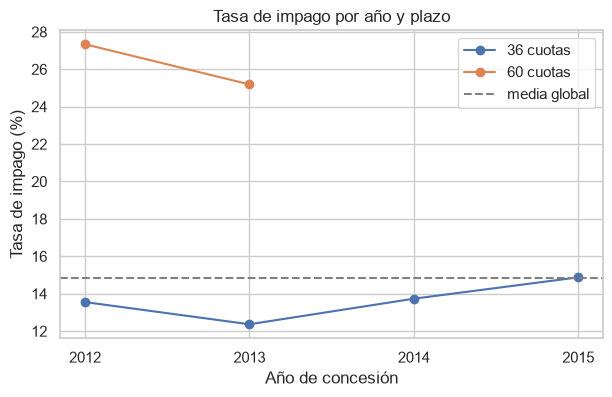

In [6]:
# Gráfico: tasa de impago por año de concesión, una línea por plazo
fig, ax = plt.subplots(figsize=(7, 4))
for plazo, serie in impago.groupby([df['num_cuotas'], anio]).mean().groupby(level=0):
    # serie tiene índice (plazo, año): nos quedamos con el año para el eje X
    ax.plot(serie.index.get_level_values(1), serie.values * 100, marker='o', label=f'{plazo} cuotas')
ax.axhline(TASA_IMPAGO_GLOBAL * 100, color='grey', linestyle='--', label='media global')  # referencia
ax.set_xticks(sorted(anio.unique()))           # un tick por año
ax.set_xlabel('Año de concesión')
ax.set_ylabel('Tasa de impago (%)')
ax.set_title('Tasa de impago por año y plazo')
ax.legend()
plt.show()

**Qué se hace:** la misma información de la tabla anterior en un gráfico: una línea por plazo y la media global como referencia.

**Qué se observa:** la línea de 60 cuotas queda muy por encima de la de 36 en los dos años en que coinciden. La de 36 cuotas es bastante estable (sin tendencia clara), lo que apoya usar todos los años juntos.

<a id="s4"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">4 · HERRAMIENTAS DEL ANÁLISIS</span>

</div>

Para cada variable se repite el mismo análisis, así que se definen dos funciones:

- **`tabla_riesgo`**: divide la variable en grupos (sus categorías o, si es numérica continua, 10 tramos con el mismo nº de préstamos, llamados **deciles**) y calcula para cada grupo el nº de préstamos, la tasa de impago y el **WoE**.
- **`grafico_riesgo`**: dibuja la tasa de impago de cada grupo frente a la media global.

**Dos medidas habituales en *scoring* de crédito:**
- **WoE** (*Weight of Evidence*) de un grupo = ln(% de buenos del grupo / % de malos del grupo). Es positivo si el grupo tiene **menos** impago que la media y negativo si tiene más.
- **IV** (*Information Value*) de la variable = suma de (% buenos − % malos) × WoE en todos los grupos. Resume en un número cuánto separa la variable a los buenos de los malos. Escala habitual: < 0,02 sin poder predictivo · 0,02–0,1 débil · 0,1–0,3 medio · > 0,3 fuerte.

> En la sección [4.1](#s4-1) se explica con un ejemplo paso a paso cómo se calculan y cómo se interpretan.

> El IV es una primera criba **univariante** (cada variable por separado). No ve interacciones ni redundancias entre variables: eso se revisa después con las correlaciones.

In [7]:
def agrupar(serie, n_tramos=10, max_categorias=12):
    '''Devuelve la variable convertida en grupos para el análisis de riesgo.

    - Texto, categoría o numérica con pocos valores distintos (<= max_categorias): cada valor es un grupo.
    - Numérica continua: n_tramos tramos con el mismo nº de préstamos (cuantiles).
    '''
    es_numerica = pd.api.types.is_numeric_dtype(serie)
    if es_numerica and serie.nunique() > max_categorias:
        # qcut corta por cuantiles; duplicates='drop' une tramos si muchos préstamos comparten el mismo valor
        return pd.qcut(serie, q=n_tramos, duplicates='drop')
    return serie    # se usa tal cual (las categorías ordenadas del notebook 02 conservan su orden)


def tabla_riesgo(variable, n_tramos=10):
    '''Tabla de riesgo de una variable: préstamos, tasa de impago y WoE por grupo, más su IV.

    variable : nombre de una columna de df o una serie de pandas ya preparada
    '''
    # 'variable' puede ser el nombre de una columna de df o una serie ya preparada (p. ej. recortada)
    serie = df[variable] if isinstance(variable, str) else variable
    grupos = agrupar(serie, n_tramos)
    # observed=True: solo los grupos que existen (evita filas vacías con categorías ordenadas)
    tabla = impago.groupby(grupos, observed=True).agg(n_prestamos='size', n_impagos='sum')
    tabla['n_buenos'] = tabla['n_prestamos'] - tabla['n_impagos']
    tabla['%_prestamos'] = tabla['n_prestamos'] / tabla['n_prestamos'].sum() * 100
    tabla['tasa_impago'] = tabla['n_impagos'] / tabla['n_prestamos']
    # Reparto de buenos y malos entre los grupos (0.5 evita dividir por 0 en grupos sin impagos)
    pct_buenos = (tabla['n_buenos'] + 0.5) / tabla['n_buenos'].sum()
    pct_malos = (tabla['n_impagos'] + 0.5) / tabla['n_impagos'].sum()
    tabla['woe'] = np.log(pct_buenos / pct_malos)
    # Aportación de cada grupo al IV; la suma es el IV de la variable
    tabla['iv'] = (pct_buenos - pct_malos) * tabla['woe']
    tabla.index = tabla.index.astype(str)    # etiquetas legibles para los gráficos
    return tabla[['n_prestamos', '%_prestamos', 'tasa_impago', 'woe', 'iv']]


def grafico_riesgo(variable, n_tramos=10, ax=None):
    '''Barras con la tasa de impago de cada grupo y la media global como referencia.'''
    tabla = tabla_riesgo(variable, n_tramos)
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 4))
    ax.bar(tabla.index, tabla['tasa_impago'] * 100, color='#1f4e79')
    ax.axhline(TASA_IMPAGO_GLOBAL * 100, color='grey', linestyle='--', label='media global')
    nombre = variable if isinstance(variable, str) else variable.name   # título del gráfico
    ax.set_title(f"{nombre} · IV = {tabla['iv'].sum():.3f}")
    ax.set_ylabel('Tasa de impago (%)')
    ax.tick_params(axis='x', rotation=45)    # etiquetas inclinadas para que no se pisen
    for etiqueta in ax.get_xticklabels():
        etiqueta.set_horizontalalignment('right')
    ax.legend()
    return ax

# Prueba de las funciones con una variable conocida: el plazo
tabla_riesgo('num_cuotas')

,n_prestamos,%_prestamos,tasa_impago,woe,iv
num_cuotas,,,,,
36,412328,92.991,0.140,0.066,0.004
60,31077,7.009,0.257,-0.683,0.041


**Qué se hace:** se definen las funciones `agrupar`, `tabla_riesgo` y `grafico_riesgo`, y se prueban con `num_cuotas`.

**Qué se observa:** la tabla del plazo reproduce lo visto en la sección 3 (14,0 % de impago a 36 cuotas y 25,7 % a 60). El WoE es positivo en 36 cuotas (menos impago que la media) y claramente negativo en 60. Su IV (≈ 0,045) es **débil**: aunque la diferencia de riesgo es grande, solo el 7 % de los préstamos son a 60 cuotas.

<a id="s4-1"></a>

### 4.1 · WoE e IV explicados con un ejemplo

La idea de las dos medidas es ver **cómo se reparten los préstamos buenos (devueltos) y los malos (impagados) entre los grupos de una variable**. Si una variable no tuviera relación con el impago, cada grupo tendría el mismo % de los buenos que de los malos. Cuanto más se alejan esos dos porcentajes, más información aporta la variable.

**1 · WoE (*Weight of Evidence*, «peso de la evidencia») de un grupo**

$$\text{WoE} = \ln\left(\frac{\%\ \text{de todos los buenos que hay en el grupo}}{\%\ \text{de todos los malos que hay en el grupo}}\right)$$

- **0** → el grupo tiene el riesgo medio.
- **Positivo** → hay más buenos de los que le tocarían: **menos riesgo** que la media.
- **Negativo** → hay más malos de los que le tocarían: **más riesgo** que la media.
- El logaritmo lo hace simétrico: el doble de buenos da +0,69 y el doble de malos, −0,69.

**2 · IV (*Information Value*, «valor de información») de la variable**

$$\text{IV} = \sum_{\text{grupos}} (\%\ \text{buenos} - \%\ \text{malos}) \times \text{WoE}$$

Cada término es siempre positivo (los dos factores tienen el mismo signo). Un grupo aporta mucho al IV si es **grande** (el primer factor es grande) y además **distinto de la media** (WoE lejos de 0). Por eso `num_cuotas` tiene un IV bajo aunque las de 60 cuotas impagan el doble: solo son el 7 % de los préstamos.

La celda siguiente calcula las dos medidas **a mano** para `vivienda`.

In [8]:
# Nº de buenos (devueltos) y malos (impagados) de cada tipo de vivienda
ejemplo = pd.DataFrame({
    'malos': impago.groupby(df['vivienda']).sum(),                   # impago = 1
    'buenos': (1 - impago).groupby(df['vivienda']).sum(),            # impago = 0
})

# Paso 1: qué % de TODOS los buenos y de TODOS los malos cae en cada grupo (cada columna suma 1)
ejemplo['%_buenos'] = ejemplo['buenos'] / ejemplo['buenos'].sum()
ejemplo['%_malos'] = ejemplo['malos'] / ejemplo['malos'].sum()

# Paso 2: WoE de cada grupo = ln(% buenos / % malos)
ejemplo['woe'] = np.log(ejemplo['%_buenos'] / ejemplo['%_malos'])

# Paso 3: aportación de cada grupo al IV = (% buenos − % malos) × WoE
ejemplo['iv'] = (ejemplo['%_buenos'] - ejemplo['%_malos']) * ejemplo['woe']

print(f"IV de vivienda = suma de la columna 'iv' = {ejemplo['iv'].sum():.3f}")
ejemplo

IV de vivienda = suma de la columna 'iv' = 0.032


,malos,buenos,%_buenos,%_malos,woe,iv
vivienda,,,,,,
MORTGAGE,26623,185734,0.492,0.404,0.196,0.017
OWN,6940,37573,0.100,0.105,-0.058,0.000
RENT,32275,154260,0.409,0.490,-0.182,0.015


**Qué se hace:** se cuentan los buenos y los malos de cada tipo de vivienda y se calculan, paso a paso, el reparto de cada uno entre los grupos, el WoE y la aportación de cada grupo al IV.

**Qué se observa:**
- `MORTGAGE` tiene el **49,2 %** de todos los buenos, pero solo el **40,4 %** de los malos: WoE = ln(49,2 / 40,4) = **+0,196**, menos riesgo que la media.
- `RENT` tiene el 40,9 % de los buenos y el **49,0 %** de los malos: WoE = **−0,182**, más riesgo.
- `OWN` tiene casi el mismo % de buenos que de malos (10,0 % y 10,5 %): WoE ≈ −0,06, casi el riesgo medio, y apenas aporta al IV.
- **IV = 0,017 + 0,0003 + 0,015 ≈ 0,032** (variable débil). Coincide con lo que calcula `tabla_riesgo('vivienda')`, que además suma 0,5 a cada recuento para no dividir por 0 en grupos sin impagos.

**Escala habitual del IV:** < 0,02 sin poder predictivo · 0,02–0,1 débil · 0,1–0,3 medio · > 0,3 fuerte. Un IV **mayor que 0,5 es sospechoso**: suele indicar *leakage* (una variable que «sabe» el resultado).

**Por qué se usan en *scoring* de crédito:**
- **El WoE es un *log-odds*:** equivale a ln(odds del grupo / odds global), con odds = buenos / malos. La regresión logística trabaja justo en esa escala, así que sustituir cada categoría por su WoE da una relación lineal con el riesgo y **una sola columna por variable** en lugar de una por categoría.
- **El IV permite ordenar las variables** rápidamente antes de modelizar (sección 5).

**Sus límites** (por eso la sección 11 hace también una comprobación conjunta):
- **Mira cada variable por separado:** `ingresos` tiene un IV alto pero, junto al ratio importe / ingresos y al DTI, apenas aporta; `saldo_revolving` tiene un IV bajo pero sí aporta en conjunto.
- **Depende de cómo se agrupe:** con deciles o con otros cortes, el IV de una variable numérica cambia algo.
- **Los grupos muy pequeños dan WoE inestables:** pocos casos hacen que el cociente cambie mucho con unos pocos impagos de más o de menos.

<a id="s4-2"></a>

### 4.2 · PSI: estabilidad de una variable en el tiempo

El **PSI** (*Population Stability Index*, «índice de estabilidad de la población») no mide riesgo, sino **si los datos cambian con el tiempo**. Compara cómo se reparten los préstamos entre los grupos (o tramos) de una variable en dos periodos: uno de **referencia** (por ejemplo, el de entrenamiento) y uno **actual** (por ejemplo, los clientes de este mes).

$$\text{PSI} = \sum_{\text{grupos}} (\%\ \text{actual} - \%\ \text{referencia}) \times \ln\left(\frac{\%\ \text{actual}}{\%\ \text{referencia}}\right)$$

Es la **misma fórmula que el IV**, pero en lugar de comparar buenos con malos compara periodo antiguo con periodo nuevo. Cada término es siempre positivo: un grupo aporta mucho si su peso **cambia mucho** entre los dos periodos.

**Escala habitual:** < 0,1 estable · 0,1–0,25 cambio moderado (vigilar) · > 0,25 cambio importante (el modelo puede fallar con esa variable).

**Por qué importa:** un modelo aprende con los clientes del pasado. Si los clientes nuevos se reparten de otra forma (por ejemplo, muchos más alquileres), las predicciones pueden dejar de ser fiables. Los bancos calculan el PSI de cada variable cada mes con los modelos en producción para saber cuándo hay que **reentrenar**.

In [ ]:
def psi(referencia, actual):
    '''Population Stability Index entre dos repartos de una misma variable (ya en grupos o tramos).

    referencia : serie con los grupos de cada préstamo en el periodo de referencia
    actual     : serie con los grupos de cada préstamo en el periodo actual
    '''
    p_ref = referencia.value_counts(normalize=True)                   # % de préstamos en cada grupo (referencia)
    p_act = actual.value_counts(normalize=True)                       # % de préstamos en cada grupo (actual)
    p_ref, p_act = p_ref.align(p_act, fill_value=0)                   # mismos grupos en los dos (0 si falta alguno)
    p_ref, p_act = p_ref.clip(lower=1e-4), p_act.clip(lower=1e-4)     # evitar ln(0) en grupos vacíos
    return ((p_act - p_ref) * np.log(p_act / p_ref)).sum()

# Ejemplo paso a paso con vivienda: referencia = 2012-2013, actual = 2015
ref = df.loc[anio.isin([2012, 2013]), 'vivienda'].value_counts(normalize=True)
act = df.loc[anio == 2015, 'vivienda'].value_counts(normalize=True)
ejemplo_psi = pd.DataFrame({'%_2012-13': ref, '%_2015': act})
ejemplo_psi['diferencia'] = ejemplo_psi['%_2015'] - ejemplo_psi['%_2012-13']           # cuánto cambia el peso del grupo
ejemplo_psi['ln_cociente'] = np.log(ejemplo_psi['%_2015'] / ejemplo_psi['%_2012-13'])  # cambio relativo (en logaritmo)
ejemplo_psi['aportacion'] = ejemplo_psi['diferencia'] * ejemplo_psi['ln_cociente']     # aportación al PSI

print(f"PSI de vivienda (2015 frente a 2012-2013) = {ejemplo_psi['aportacion'].sum():.3f}")
print(f"Con la función psi():                      {psi(df.loc[anio.isin([2012, 2013]), 'vivienda'], df.loc[anio == 2015, 'vivienda']):.3f}")
ejemplo_psi

**Qué se hace:** se define la función `psi` (se usará en la sección 9) y se calcula paso a paso el PSI de `vivienda` entre 2012–2013 y 2015: el % de préstamos de cada tipo de vivienda en cada periodo, la diferencia, el logaritmo del cociente y la aportación de cada grupo.

**Qué se observa:** el reparto de la vivienda apenas cambia entre los dos periodos (unos pocos puntos de diferencia en cada grupo), así que el PSI es muy bajo (≈ 0,02): **variable estable**. Como contraste, en la sección 9 se verá que `sector_empleo` tiene un PSI de ≈ 1 porque en 2012–2013 el 59 % de los préstamos estaba en `otros` y en 2015 solo el 14 %.

<a id="s5"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">5 · VISIÓN GENERAL: PODER PREDICTIVO DE CADA VARIABLE</span>

</div>

In [9]:
def clasificar_iv(iv):
    '''Etiqueta del poder predictivo según la escala habitual del IV.'''
    if iv < 0.02:
        return 'sin poder'
    if iv < 0.1:
        return 'débil'
    if iv < 0.3:
        return 'medio'
    return 'fuerte'

# IV de cada variable candidata y de las de benchmark (para comparar)
ranking = pd.DataFrame({
    'iv': [tabla_riesgo(v)['iv'].sum() for v in CANDIDATAS + BENCHMARK],
    'grupo': ['candidata'] * len(CANDIDATAS) + ['benchmark'] * len(BENCHMARK),
}, index=CANDIDATAS + BENCHMARK).sort_values('iv', ascending=False)
ranking['poder_predictivo'] = ranking['iv'].apply(clasificar_iv)
ranking

,iv,grupo,poder_predictivo
subrating,0.390,benchmark,fuerte
rating,0.355,benchmark,fuerte
tipo_interes,0.350,benchmark,fuerte
fico,0.128,candidata,medio
ingresos,0.057,candidata,débil
dti,0.051,candidata,débil
num_cuotas,0.045,candidata,débil
num_consultas_6meses,0.038,candidata,débil
sector_empleo,0.038,candidata,débil
ingresos_verificados,0.038,candidata,débil


**Qué se hace:** se calcula el IV de las 23 variables candidatas y, como comparación, de las 4 de *benchmark*, y se ordenan de mayor a menor.

**Qué se observa:**
- Las variables de **benchmark** son las más fuertes (`subrating` ≈ 0,39, `rating` y `tipo_interes` ≈ 0,35): resumen el análisis de riesgo que ya hizo Lending Club. Por eso no entran en el modelo principal (D12 del notebook 02): sirven de **listón** a superar. `imp_cuota` apenas separa por sí sola porque depende sobre todo del importe del préstamo.
- Entre las candidatas, **`fico` es la única con poder medio** (≈ 0,13).
- Un grupo **débil** (0,02–0,06): `ingresos`, `dti`, `num_cuotas`, `sector_empleo`, `num_consultas_6meses`, `ingresos_verificados`, `porc_tarjetas_75p`, `porc_uso_tarjetas`, `vivienda`, `num_hipotecas` y `finalidad`.
- **Sin poder predictivo por sí solas** (< 0,02): `porc_uso_revolving` (justo en el límite, 0,019), `antigüedad_empleo`, `saldo_revolving`, `principal`, `tramo_ult_retraso` y los recuentos de incidencias (`num_retrasos_2anios`, `num_derogatorios`, `num_quiebras`, `num_cancelaciones_12meses`) y de líneas de crédito.

> Que una variable tenga un IV bajo **no** basta para descartarla: puede aportar en combinación con otras, o tener un patrón que los deciles esconden (por ejemplo, `principal` puede importar en relación con los ingresos). Cada bloque se revisa en las secciones siguientes antes de decidir.

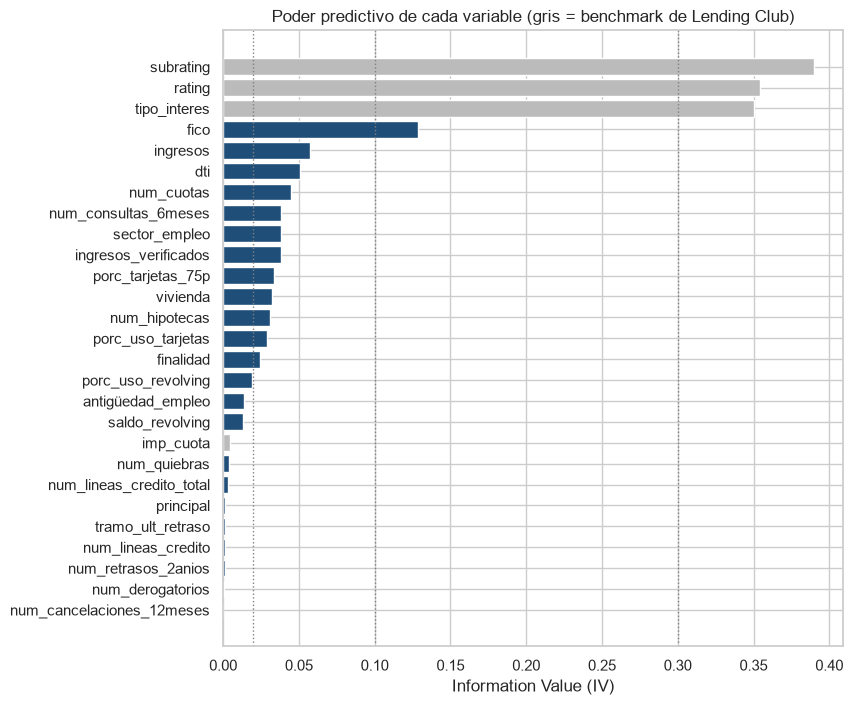

In [10]:
# Gráfico del ranking: una barra por variable, coloreada según sea candidata o benchmark
fig, ax = plt.subplots(figsize=(8, 8))
colores = ranking['grupo'].map({'candidata': '#1f4e79', 'benchmark': '#bbbbbb'})
ax.barh(ranking.index[::-1], ranking['iv'][::-1], color=colores[::-1])  # [::-1]: la más fuerte arriba
for limite in [0.02, 0.1, 0.3]:                                       # líneas de la escala del IV
    ax.axvline(limite, color='grey', linestyle=':', linewidth=1)
ax.set_xlabel('Information Value (IV)')
ax.set_title('Poder predictivo de cada variable (gris = benchmark de Lending Club)')
plt.show()

**Qué se hace:** el ranking anterior en un gráfico de barras horizontales; las líneas punteadas marcan los límites de la escala (0,02 · 0,1 · 0,3).

**Qué se observa:** se aprecia la distancia entre la evaluación de Lending Club (barras grises) y cualquier variable individual del cliente. El modelo tendrá que **combinar** muchas variables débiles para acercarse al *benchmark* (en el notebook 02, un modelo rápido con los datos del cliente ya superaba al subrating: AUC 0,680 frente a 0,669).

<a id="s6"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">6 · VARIABLES CATEGÓRICAS</span>

</div>

Para cada variable categórica se mira la tasa de impago de cada categoría y se decide si se mantiene igual, se agrupan categorías parecidas o se descarta.

<a id="s6-1"></a>

### 6.1 · `antigüedad_empleo` (D1)

**Variable analizada: `antigüedad_empleo`** · años que el cliente lleva en su empleo actual, de `< 1 year` a `10+ years`. Los nulos se convirtieron en `sin_empleo_declarado` en el notebook 02 (D2).

In [11]:
# Tabla de riesgo con las 12 categorías originales (una por año de antigüedad)
tabla_antiguedad = tabla_riesgo('antigüedad_empleo')

# Margen de error al 95 % de cada tasa: 1,96 × raíz(p × (1 − p) / n)
# Si los márgenes de dos categorías se solapan, sus tasas no se pueden distinguir
p = tabla_antiguedad['tasa_impago']
tabla_antiguedad['margen_95'] = 1.96 * np.sqrt(p * (1 - p) / tabla_antiguedad['n_prestamos'])
tabla_antiguedad[['n_prestamos', '%_prestamos', 'tasa_impago', 'margen_95', 'woe']]

,n_prestamos,%_prestamos,tasa_impago,margen_95,woe
antigüedad_empleo,,,,,
< 1 year,35183,7.935,0.154,0.004,-0.042
1 year,28614,6.453,0.153,0.004,-0.035
2 years,39891,8.997,0.147,0.003,0.009
3 years,35336,7.969,0.146,0.004,0.016
4 years,26093,5.885,0.147,0.004,0.009
5 years,28213,6.363,0.148,0.004,0.006
6 years,21739,4.903,0.149,0.005,-0.002
7 years,22565,5.089,0.149,0.005,-0.004
8 years,21938,4.948,0.148,0.005,0.005


**Qué se hace:** tasa de impago de cada año de antigüedad, con su **margen de error al 95 %** (cuánto podría variar la tasa por puro azar con ese nº de préstamos).

**Qué se observa:**
- `sin_empleo_declarado` es el grupo de más riesgo (**20,6 %**), muy por encima del resto.
- `< 1 year` (15,4 %) y `1 year` (15,3 %) son casi iguales.
- **De 2 a 9 años la tasa es plana** (14,6–15,0 %) y los márgenes de error se solapan: el modelo no podría distinguir esas categorías.
- `10+ years` es el grupo de menos riesgo (**13,7 %**).

> **Decisión D1 · Agrupar `antigüedad_empleo` en 4 categorías ordenadas: `sin_empleo_declarado` < `≤1` < `2-9` < `10+`.**
> - **Por qué:** de 2 a 9 años el impago es el mismo, así que separarlos solo añade ruido. Se mantienen los escalones que sí son distintos: sin empleo, primer año (≤ 1), y 10 años o más.
> - **Alternativas descartadas:** 3 grupos (`sin_empleo_declarado`, `<10`, `10+`), con un IV casi igual pero que mezcla el primer año con el resto; y 5 grupos (separando 1–4 y 5–9 años), cuyas tasas son iguales (14,8 % y 14,9 %).
> - **En la demo:** el formulario solo necesita preguntar por estos 4 tramos.

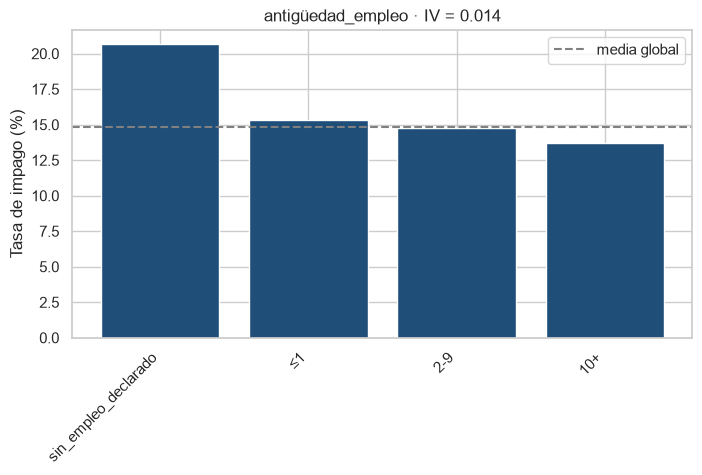

,n_prestamos,%_prestamos,tasa_impago,woe,iv
antigüedad_empleo,,,,,
sin_empleo_declarado,25319,5.710,0.206,-0.400,0.010
≤1,63797,14.388,0.153,-0.038,0.000
2-9,212884,48.011,0.148,0.005,0.000
10+,141405,31.891,0.137,0.095,0.003


In [12]:
# Mapa de las 12 categorías originales a los 4 grupos de D1
def grupo_antiguedad(categoria):
    '''Devuelve el grupo de antigüedad (D1) de una categoría original.'''
    if categoria == 'sin_empleo_declarado':
        return 'sin_empleo_declarado'      # nulo del notebook 02 (D2)
    if categoria in ['< 1 year', '1 year']:
        return '≤1'                        # primer año en el empleo
    if categoria == '10+ years':
        return '10+'                       # 10 años o más
    return '2-9'                           # de 2 a 9 años: impago plano

AGRUPAR_ANTIGUEDAD = {cat: grupo_antiguedad(cat) for cat in df['antigüedad_empleo'].cat.categories}
ORDEN_ANTIGUEDAD_EDA = ['sin_empleo_declarado', '≤1', '2-9', '10+']   # de menor a mayor estabilidad laboral

# Aplicar el mapa y guardar la variable como categoría ordenada
df['antigüedad_empleo'] = pd.Categorical(
    df['antigüedad_empleo'].map(AGRUPAR_ANTIGUEDAD),
    categories=ORDEN_ANTIGUEDAD_EDA, ordered=True,
)

# Comprobación: no se ha perdido ningún préstamo al agrupar
assert df['antigüedad_empleo'].notna().all(), "Alguna categoría no tiene grupo asignado"

# Tabla de riesgo y gráfico con los 4 grupos
grafico_riesgo('antigüedad_empleo')
plt.show()
tabla_riesgo('antigüedad_empleo')

**Qué se hace:** se aplica la decisión D1 (mapa de las 12 categorías a 4 grupos) y se repiten la tabla de riesgo y el gráfico con los grupos nuevos.

**Qué se observa:** la tasa de impago baja de forma **escalonada y ordenada**: 20,6 % (sin empleo) → 15,3 % (≤ 1 año) → 14,8 % (2–9) → 13,7 % (10+). A más estabilidad laboral, menos impago. El IV (≈ 0,0135) es el mismo que con las 12 categorías: agrupar **no pierde información** y simplifica la variable. Sigue siendo una variable débil por sí sola; si entra en el modelo se decidirá en la selección final.

<a id="s6-2"></a>

### 6.2 · `ingresos_verificados` (D2)

**Variable analizada: `ingresos_verificados`** · si Lending Club comprobó los ingresos del cliente: `Verified` (ingresos comprobados), `Source Verified` (se comprobó la fuente de los ingresos) o `Not Verified` (sin comprobar). En el notebook 02 se dejó sin cambios y se aplazó su valoración al EDA (D9 del notebook 02).

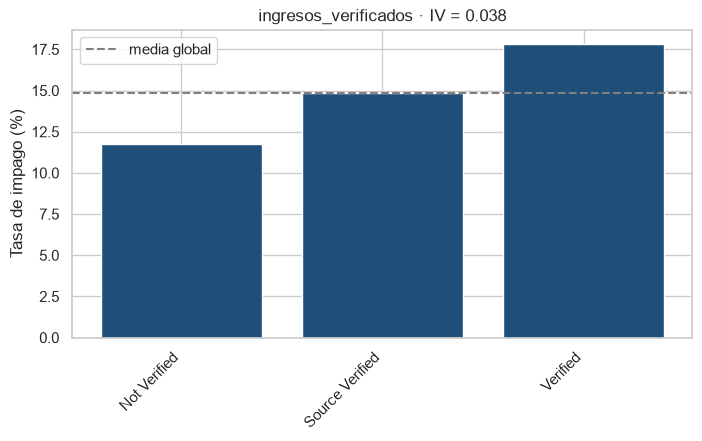

,n_prestamos,%_prestamos,tasa_impago,woe,iv
ingresos_verificados,,,,,
Not Verified,140705,31.733,0.117,0.270,0.021
Source Verified,155420,35.051,0.149,-0.000,0.000
Verified,147280,33.216,0.178,-0.217,0.017


In [13]:
# Tabla de riesgo de las 3 categorías y gráfico frente a la media global
grafico_riesgo('ingresos_verificados')
plt.show()
tabla_riesgo('ingresos_verificados')

**Qué se hace:** tasa de impago de cada estado de verificación.

**Qué se observa:** el resultado es **el contrario de lo esperado**: los préstamos con ingresos verificados impagan más (**17,8 %**) que los no verificados (**11,7 %**); `Source Verified` queda en medio (14,9 %).

In [14]:
# ¿A quién verifica Lending Club? % de cada estado de verificación dentro de cada rating
pd.crosstab(df['rating'], df['ingresos_verificados'], normalize='index')

ingresos_verificados,Not Verified,Source Verified,Verified
rating,,,
A,0.428,0.363,0.209
B,0.356,0.357,0.287
C,0.265,0.360,0.375
D,0.239,0.321,0.440
E,0.139,0.310,0.551
F,0.095,0.243,0.662
G,0.031,0.267,0.702


**Qué se hace:** para cada rating de Lending Club, qué % de préstamos tiene cada estado de verificación (cada fila suma 1).

**Qué se observa:** Lending Club **no verifica al azar**: verifica sobre todo a quien considera más arriesgado. Los préstamos `Verified` pasan del 21 % en el rating A al 70 % en el G. Lo mismo ocurre con el importe: cuanto más dinero se pide, más se verifica.

In [15]:
# ¿Se mantiene la diferencia dentro del mismo rating? Tasa de impago por rating y verificación
impago.groupby([df['rating'], df['ingresos_verificados']], observed=True).mean().unstack()

ingresos_verificados,Not Verified,Source Verified,Verified
rating,,,
A,0.049,0.059,0.058
B,0.107,0.115,0.120
C,0.166,0.188,0.193
D,0.209,0.246,0.251
E,0.258,0.300,0.306
F,0.288,0.352,0.353
G,0.212,0.369,0.403


**Qué se hace:** tasa de impago por rating (filas) y estado de verificación (columnas), para comparar préstamos con la misma evaluación de Lending Club.

**Qué se observa:** incluso **dentro del mismo rating**, los verificados impagan más (por ejemplo, en el rating C: 16,6 % sin verificar frente a 19,3 % verificados). La variable recoge una **sospecha interna de Lending Club** (por qué decidió investigar a ese cliente) que el rating no captura del todo.

> **Decisión D2 · Pasar `ingresos_verificados` al grupo *benchmark*: no será entrada del modelo principal.**
> - **Por qué:** no describe al cliente, sino una **decisión del prestamista** (a quién investigar), igual que `rating`, `subrating`, `tipo_interes` e `imp_cuota` (D12 del notebook 02).
> - **En la demo** quien solicita el préstamo no sabe si se le va a verificar, así que no se puede pedir en el formulario.
> - **Incentivo perverso:** un modelo que la usara penalizaría tener los ingresos verificados, algo difícil de justificar ante un supervisor o un cliente.
> - **Coste bajo:** su IV es débil (≈ 0,038).
> - **Alternativa descartada:** mantenerla y fijarla siempre en `Not Verified` en la demo; el modelo aprendería un efecto que nunca se usaría.

In [16]:
# Aplicar D2: sacar la variable de las candidatas y añadirla al benchmark
CANDIDATAS.remove('ingresos_verificados')
BENCHMARK.append('ingresos_verificados')
print(f"Candidatas: {len(CANDIDATAS)} · Benchmark: {BENCHMARK}")

Candidatas: 22 · Benchmark: ['rating', 'subrating', 'tipo_interes', 'imp_cuota', 'ingresos_verificados']


**Qué se hace:** se mueve `ingresos_verificados` de la lista de candidatas a la de *benchmark* (la variable se conserva en los datos para poder analizarla).

**Qué se observa:** quedan **22 variables candidatas** y 5 de *benchmark*.

<a id="s6-3"></a>

### 6.3 · `vivienda` (D3)

**Variable analizada: `vivienda`** · situación de la vivienda del cliente: `MORTGAGE` (propia con hipoteca), `OWN` (propia sin hipoteca) o `RENT` (alquiler). Las categorías residuales (`NONE`, `OTHER`, `ANY`) se eliminaron en el notebook 02 (D10).

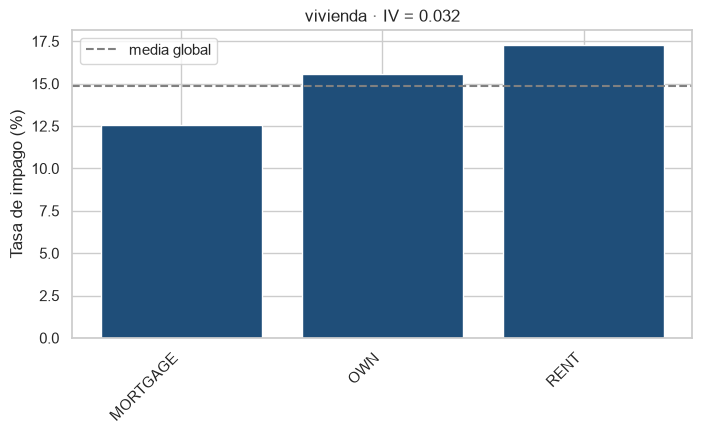

,n_prestamos,%_prestamos,tasa_impago,woe,iv,ingresos_mediana
vivienda,,,,,,
MORTGAGE,212357,47.892,0.125,0.196,0.017,72000.000
OWN,44513,10.039,0.156,-0.058,0.000,54000.000
RENT,186535,42.069,0.173,-0.182,0.015,53000.000


In [17]:
# Tabla de riesgo de las 3 categorías y gráfico frente a la media global
grafico_riesgo('vivienda')
plt.show()
tabla_vivienda = tabla_riesgo('vivienda')

# Añadir la mediana de ingresos de cada grupo para entender su perfil
tabla_vivienda['ingresos_mediana'] = df.groupby('vivienda')['ingresos'].median()
tabla_vivienda

**Qué se hace:** tasa de impago de cada tipo de vivienda, junto con la mediana de ingresos de cada grupo.

**Qué se observa:** `MORTGAGE` es el grupo de menos riesgo (**12,5 %**), `OWN` queda en medio (15,6 %) y `RENT` es el de más riesgo (**17,3 %**). Los clientes con hipoteca también tienen más ingresos (mediana de 72.000 $ frente a unos 53.000 $), así que hay que comprobar si la vivienda aporta algo más allá de los ingresos.

In [18]:
# ¿Se mantiene el orden con los mismos ingresos y el mismo FICO?
# Se divide cada variable en 3 tramos con el mismo nº de préstamos (terciles)
tercil_ingresos = pd.qcut(df['ingresos'], 3, labels=['ingresos bajos', 'ingresos medios', 'ingresos altos'])
tercil_fico = pd.qcut(df['fico'], 3, labels=['FICO bajo', 'FICO medio', 'FICO alto'])

# Tasa de impago por tramo (filas) y tipo de vivienda (columnas)
por_ingresos = impago.groupby([tercil_ingresos, df['vivienda']], observed=True).mean().unstack()
por_fico = impago.groupby([tercil_fico, df['vivienda']], observed=True).mean().unstack()
pd.concat([por_ingresos, por_fico])     # una tabla debajo de la otra

vivienda,MORTGAGE,OWN,RENT
ingresos bajos,0.158,0.177,0.195
ingresos medios,0.132,0.147,0.166
ingresos altos,0.103,0.126,0.137
FICO bajo,0.166,0.200,0.210
FICO medio,0.135,0.159,0.173
FICO alto,0.082,0.104,0.113


**Qué se hace:** tasa de impago por tipo de vivienda dentro de cada tercil de ingresos y de FICO, para comparar clientes parecidos.

**Qué se observa:** el orden **MORTGAGE < OWN < RENT se mantiene en todos los tramos** (por ejemplo, con ingresos altos: 10,3 % / 12,6 % / 13,7 %; con FICO alto: 8,2 % / 10,4 % / 11,3 %). La vivienda aporta información propia. Que `OWN` salga peor que `MORTGAGE` tiene una explicación probable: tener una hipoteca significa que un banco ya concedió crédito al cliente y la está pagando (solvencia demostrada).

> **Relación con `num_hipotecas`:** casi todos los `MORTGAGE` tienen al menos una hipoteca y casi todos los `RENT` ninguna, pero `num_hipotecas` sigue separando el riesgo dentro de cada tipo de vivienda. La redundancia entre ambas se revisa en la sección de correlaciones.

> **Decisión D3 · Mantener `vivienda` sin cambios (3 categorías) como variable candidata.**
> - **Por qué:** las tres categorías tienen riesgos claramente distintos, también entre clientes con los mismos ingresos y el mismo FICO (IV ≈ 0,032, débil pero propio).
> - **En la demo:** es una pregunta sencilla del formulario, con 3 opciones.

<a id="s6-4"></a>

### 6.4 · `finalidad` (D4)

**Variable analizada: `finalidad`** · para qué pide el cliente el préstamo. Tras el notebook 02 (D11) quedan 11 categorías.

In [19]:
# Tabla de riesgo de las 11 finalidades, ordenada de menor a mayor tasa de impago
tabla_finalidad = tabla_riesgo('finalidad').sort_values('tasa_impago')

# Margen de error al 95 % de cada tasa (las categorías pequeñas tienen más incertidumbre)
p = tabla_finalidad['tasa_impago']
tabla_finalidad['margen_95'] = 1.96 * np.sqrt(p * (1 - p) / tabla_finalidad['n_prestamos'])
tabla_finalidad

,n_prestamos,%_prestamos,tasa_impago,woe,iv,margen_95
finalidad,,,,,,
credit_card,107721,24.294,0.122,0.227,0.012,0.002
car,4350,0.981,0.124,0.209,0.000,0.010
home_improvement,25428,5.735,0.131,0.146,0.001,0.004
major_purchase,9278,2.092,0.133,0.125,0.000,0.007
debt_consolidation,256774,57.910,0.157,-0.066,0.003,0.001
vacation,2771,0.625,0.159,-0.080,0.000,0.014
other,22965,5.179,0.172,-0.178,0.002,0.005
medical,4575,1.032,0.176,-0.206,0.000,0.011
house,1771,0.399,0.182,-0.247,0.000,0.018


**Qué se hace:** tasa de impago y margen de error de cada finalidad, ordenadas de menos a más riesgo.

**Qué se observa:**
- Dos finalidades concentran el **82 %** de los préstamos y tienen riesgos distintos: pagar tarjetas (`credit_card`, **12,2 %**) frente a unificar deudas (`debt_consolidation`, **15,7 %**).
- Los extremos tienen sentido de negocio: las compras concretas y planificadas (coche, reformas, compra grande) tienen poco riesgo (12–13 %); el negocio propio (`small_business`, **24,1 %**), la mudanza (20,2 %) o los gastos médicos (17,6 %) suelen ir con ingresos inciertos o imprevistos.
- Las categorías pequeñas tienen márgenes de ±1–2 puntos, pero todas superan los 1.700 préstamos.

In [20]:
# ¿Se mantiene el efecto con el mismo FICO? Tasa de impago por finalidad y tercil de FICO
tercil_fico = pd.qcut(df['fico'], 3, labels=['FICO bajo', 'FICO medio', 'FICO alto'])
impago.groupby([df['finalidad'], tercil_fico], observed=True).mean().unstack().loc[tabla_finalidad.index]

fico,FICO bajo,FICO medio,FICO alto
finalidad,,,
credit_card,0.164,0.128,0.072
car,0.172,0.151,0.070
home_improvement,0.166,0.146,0.090
major_purchase,0.173,0.150,0.092
debt_consolidation,0.200,0.162,0.099
vacation,0.175,0.145,0.152
other,0.203,0.177,0.127
medical,0.223,0.173,0.120
house,0.250,0.176,0.127


**Qué se hace:** tasa de impago de cada finalidad dentro de cada tercil de FICO (mismo orden que la tabla anterior).

**Qué se observa:** las diferencias se mantienen con el mismo FICO (por ejemplo, con FICO bajo: 16,4 % en `credit_card` frente a 28,5 % en `small_business`). La finalidad aporta información que el historial de crédito no recoge.

> **Decisión D4 · Mantener `finalidad` sin cambios (11 categorías) como variable candidata.**
> - **Por qué:** cada categoría tiene un significado claro, casos suficientes y un riesgo distinto.
> - **Alternativa descartada:** agrupar por nivel de riesgo (unos 6 bloques). El IV queda igual (≈ 0,024) y se mezclarían finalidades sin relación entre sí.
> - **En la demo:** ya es un desplegable del formulario. Si el modelo lo necesita, en el notebook 04 se puede codificar con su WoE (un solo número por categoría).

<a id="s6-5"></a>

### 6.5 · `sector_empleo` (D5)

**Variable analizada: `sector_empleo`** · sector del empleo del cliente, creado en el notebook 02 (D3) a partir del texto libre del puesto con reglas de palabras clave: 13 sectores, `otros` y `sin_empleo_declarado`.

In [21]:
# Tabla de riesgo por sector, ordenada de menor a mayor tasa de impago
tabla_sector = tabla_riesgo('sector_empleo').sort_values('tasa_impago')

# Mediana de ingresos de cada sector, para ver si el sector es solo un reflejo de los ingresos
tabla_sector['ingresos_mediana'] = df.groupby('sector_empleo')['ingresos'].median()
tabla_sector

,n_prestamos,%_prestamos,tasa_impago,woe,iv,ingresos_mediana
sector_empleo,,,,,,
tecnologia,22985,5.184,0.096,0.495,0.011,85000.000
legal,4523,1.020,0.106,0.386,0.001,75000.000
educacion,22022,4.967,0.123,0.221,0.002,60000.000
finanzas,21754,4.906,0.123,0.213,0.002,63000.000
direccion_gestion,60915,13.738,0.132,0.134,0.002,76800.000
administrativo,44414,10.017,0.135,0.107,0.001,55000.000
seguridad_publica,15020,3.387,0.142,0.054,0.000,65500.000
salud,34825,7.854,0.143,0.043,0.000,65000.000
otros,107847,24.322,0.159,-0.078,0.002,60000.000


**Qué se hace:** tasa de impago de cada sector, junto con la mediana de ingresos del sector.

**Qué se observa:** el impago va del **9,6 %** (tecnología) y 10,6 % (legal) al **20,0 %** (hostelería) y 20,3 % (sin empleo declarado). Los sectores de menos riesgo son también los de más ingresos (tecnología 85.000 $ frente a hostelería 41.000 $), así que hay que comprobar si el sector aporta algo más que los ingresos.

In [22]:
# Tasa de impago por sector (filas) y tercil de ingresos (columnas): compara clientes con ingresos parecidos
tercil_ingresos = pd.qcut(df['ingresos'], 3, labels=['ingresos bajos', 'ingresos medios', 'ingresos altos'])
impago.groupby([df['sector_empleo'], tercil_ingresos], observed=True).mean().unstack().loc[tabla_sector.index]

ingresos,ingresos bajos,ingresos medios,ingresos altos
sector_empleo,,,
tecnologia,0.144,0.100,0.085
legal,0.166,0.113,0.075
educacion,0.142,0.123,0.100
finanzas,0.153,0.121,0.096
direccion_gestion,0.171,0.149,0.105
administrativo,0.159,0.127,0.105
seguridad_publica,0.174,0.145,0.114
salud,0.173,0.146,0.115
otros,0.187,0.158,0.122


**Qué se hace:** tasa de impago por sector dentro de cada tercil de ingresos.

**Qué se observa:** con los mismos ingresos las diferencias se mantienen (con ingresos altos: tecnología 8,5 % frente a hostelería 17,1 % y transporte 16,9 %). El sector refleja algo más que el nivel de ingresos, probablemente la **estabilidad del empleo**.

> **Decisión D5 · Mantener `sector_empleo` como variable candidata, con vigilancia ética.**
> - **Por qué:** separa el riesgo incluso entre clientes con los mismos ingresos (y, como se vio en el notebook 02, con el mismo rating).
> - **Riesgo ético:** algunos sectores están muy asociados al sexo o al origen de las personas (por ejemplo, salud y educación frente a transporte y oficios). Un modelo podría usar el sector como **sustituto** (*proxy*) de esas características protegidas. Este dataset no tiene esos datos, así que no se puede comprobar directamente.
> - **Cómo se vigila:** en el notebook 05 se comparará el modelo con y sin `sector_empleo`. Si lo que aporta es pequeño, se quitará (en la sección 11 de este notebook ya se ve que aporta unas milésimas de AUC).
> - **Relación con `antigüedad_empleo`:** las dos tienen la categoría `sin_empleo_declarado` (coinciden en el 99 % de los casos). Se revisa en la sección 8.

<a id="s6-6"></a>

### 6.6 · `tramo_ult_retraso` (D6)

**Variable analizada: `tramo_ult_retraso`** · tiempo desde el último retraso de más de 30 días en algún pago, en tramos (creada en el notebook 02, D1): `sin_retraso`, `0-24`, `25-48` o `>48` meses.

In [23]:
# Tabla de riesgo de los 4 tramos
tabla_riesgo('tramo_ult_retraso')

,n_prestamos,%_prestamos,tasa_impago,woe,iv
tramo_ult_retraso,,,,,
sin_retraso,225301,50.812,0.145,0.030,0.000
0-24,88255,19.904,0.155,-0.052,0.001
25-48,72930,16.448,0.148,0.007,0.000
>48,56919,12.837,0.154,-0.044,0.000


**Qué se hace:** tasa de impago de cada tramo.

**Qué se observa:** las tasas son casi iguales (14,5 % a 15,5 %) y el IV es prácticamente 0 (≈ 0,001). Tener un retraso reciente **no** se asocia a más impago en estos datos.

In [24]:
# ¿Aparece el efecto al comparar clientes con el mismo FICO?
impago.groupby([df['tramo_ult_retraso'], tercil_fico], observed=True).mean().unstack()

fico,FICO bajo,FICO medio,FICO alto
tramo_ult_retraso,,,
sin_retraso,0.207,0.166,0.093
0-24,0.178,0.143,0.106
25-48,0.181,0.139,0.095
>48,0.189,0.145,0.093


**Qué se hace:** tasa de impago por tramo dentro de cada tercil de FICO.

**Qué se observa:** tampoco: con FICO bajo, los clientes **sin** retrasos impagan incluso algo más (20,7 %) que los que tienen un retraso reciente (17,8 %). Una explicación probable es la **selección de Lending Club**: solo concedía el préstamo a clientes con retrasos si el resto de su perfil era bueno, así que entre los aceptados el retraso ya no distingue el riesgo.

> **Decisión D6 · Descartar `tramo_ult_retraso`.**
> - **Por qué:** no separa el riesgo ni sola ni con el mismo FICO, y en la comprobación conjunta de la sección 11 tampoco aporta. Pedirla en el formulario de la demo no tendría ningún efecto.

<a id="s6-7"></a>

### 6.7 · `num_cuotas` (D7)

**Variable analizada: `num_cuotas`** · plazo del préstamo: 36 o 60 cuotas mensuales (convertida a número en el notebook 02, D7). Ya se analizó en las secciones 3 y 4.

> **Decisión D7 · Mantener `num_cuotas` sin cambios como variable candidata.**
> - **Por qué:** los préstamos a 60 cuotas impagan casi el doble que los de 36 en los mismos años (25–27 % frente a 12–14 %, sección 3). Su IV es débil (≈ 0,045) solo porque el 93 % de los préstamos son a 36 cuotas.
> - **Limitación:** en los datos solo hay préstamos a 60 cuotas de 2012 y 2013 (D5 del notebook 01). El modelo aprenderá el efecto del plazo con esos dos años.

<a id="s7"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">7 · VARIABLES NUMÉRICAS</span>

</div>

Para cada variable numérica se mira:
1. **Su distribución** (percentiles), para detectar asimetrías y valores extremos que habrá que transformar en el notebook 04.
2. **La tasa de impago por decil** (10 tramos con el mismo nº de préstamos), para ver si la relación con el impago es **monótona** (siempre sube o siempre baja), que es lo deseable en un modelo de *scoring*.

Los **recuentos** (nº de consultas, de incidencias...) tienen muchos ceros y pocos valores altos; para ellos se agrupan los valores altos en uno solo (por ejemplo, "4 o más") con `clip`.

In [25]:
def percentiles(variable):
    '''Percentiles principales de una variable numérica (en una fila).'''
    return df[variable].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).to_frame(variable).T

def analizar_numerica(variable):
    '''Muestra los percentiles, el gráfico de impago por decil y devuelve la tabla de riesgo.'''
    display(percentiles(variable))       # display: muestra una tabla en mitad de una celda
    grafico_riesgo(variable)
    plt.show()
    return tabla_riesgo(variable)

**Qué se hace:** se definen dos funciones para no repetir código en cada variable: `percentiles` (resumen de la distribución) y `analizar_numerica` (percentiles + gráfico + tabla de riesgo por deciles). Esta celda no produce ningún resultado.

<a id="s7-1"></a>

### 7.1 · `ingresos` (D8)

**Variable analizada: `ingresos`** · ingresos anuales declarados por el cliente ($).

,count,mean,std,min,1%,25%,50%,75%,99%,max
ingresos,443405.000,73310.238,65016.078,3000.000,18000.000,44400.000,62000.000,88500.000,250000.000,8900060.000


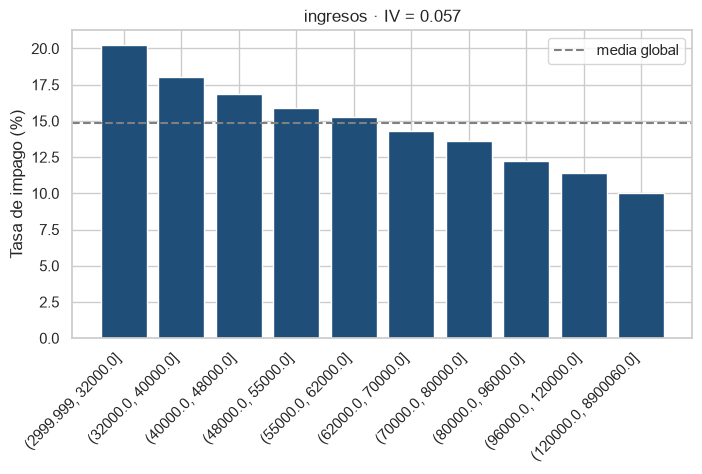

,n_prestamos,%_prestamos,tasa_impago,woe,iv
ingresos,,,,,
"(2999.999, 32000.0]",45535,10.269,0.203,-0.376,0.017
"(32000.0, 40000.0]",46822,10.560,0.181,-0.234,0.006
"(40000.0, 48000.0]",45285,10.213,0.169,-0.151,0.002
"(48000.0, 55000.0]",49500,11.164,0.159,-0.083,0.001
"(55000.0, 62000.0]",38184,8.612,0.153,-0.032,0.000
"(62000.0, 70000.0]",42781,9.648,0.143,0.043,0.000
"(70000.0, 80000.0]",42747,9.641,0.136,0.101,0.001
"(80000.0, 96000.0]",44639,10.067,0.122,0.227,0.005
"(96000.0, 120000.0]",43884,9.897,0.114,0.301,0.008


In [26]:
# Distribución, gráfico y tabla de riesgo por deciles de ingresos
analizar_numerica('ingresos')

**Qué se hace:** percentiles de los ingresos y tasa de impago por decil.

**Qué se observa:**
- La distribución es muy **asimétrica**: la mediana es 62.000 $, el percentil 99 es 250.000 $ y el máximo, 8,9 millones (extremos reales, revisados en el notebook 02, D17).
- La relación con el impago es **monótona decreciente**: del **20,3 %** en el decil más bajo (≤ 32.000 $) al **10,0 %** en el más alto (> 120.000 $). A más ingresos, menos impago, sin excepciones.

> **Decisión D8 · Mantener `ingresos` como variable candidata y aplicarle el logaritmo en el notebook 04.**
> - **Por qué:** es una de las candidatas más fuertes (IV ≈ 0,057) y su relación con el impago es ordenada.
> - **Logaritmo:** comprime los valores extremos (8,9 millones dejaría de pesar 140 veces la mediana) y hace la relación más lineal, lo que ayuda a una regresión logística.

<a id="s7-2"></a>

### 7.2 · `dti` (D9)

**Variable analizada: `dti`** · *debt-to-income*: pagos mensuales de todas las deudas (sin la hipoteca ni este préstamo) / ingresos mensuales, en %.

,count,mean,std,min,1%,25%,50%,75%,99%,max
dti,443405.000,17.803,8.184,0.000,2.090,11.630,17.310,23.570,37.020,39.990


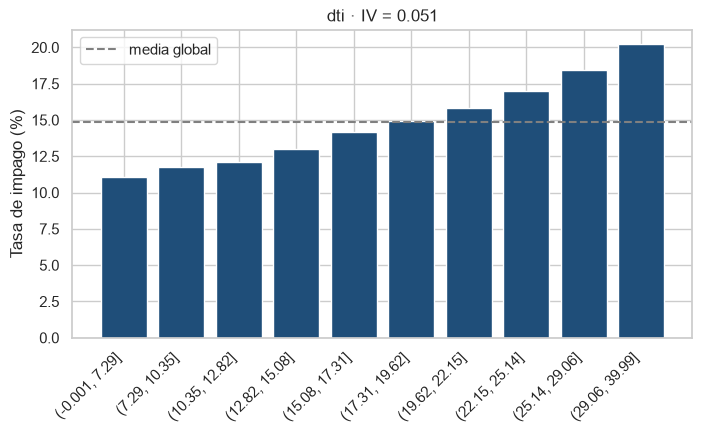

,n_prestamos,%_prestamos,tasa_impago,woe,iv
dti,,,,,
"(-0.001, 7.29]",44433,10.021,0.111,0.336,0.010
"(7.29, 10.35]",44252,9.980,0.118,0.266,0.006
"(10.35, 12.82]",44484,10.032,0.121,0.234,0.005
"(12.82, 15.08]",44382,10.009,0.130,0.154,0.002
"(15.08, 17.31]",44335,9.999,0.141,0.057,0.000
"(17.31, 19.62]",44264,9.983,0.149,-0.006,0.000
"(19.62, 22.15]",44272,9.985,0.158,-0.073,0.001
"(22.15, 25.14]",44329,9.997,0.170,-0.158,0.003
"(25.14, 29.06]",44366,10.006,0.185,-0.262,0.008


In [27]:
# Distribución, gráfico y tabla de riesgo por deciles de DTI
analizar_numerica('dti')

**Qué se hace:** percentiles del DTI y tasa de impago por decil.

**Qué se observa:** la distribución es bastante simétrica (mediana 17,3 %, máximo 40 %, que es el límite de Lending Club) y la relación con el impago es **monótona creciente**: del **11,1 %** (DTI ≤ 7 %) al **20,2 %** (DTI > 29 %). Cuanto más endeudado está el cliente respecto a sus ingresos, más impaga.

> **Decisión D9 · Mantener `dti` sin cambios como variable candidata.**
> - **Por qué:** IV ≈ 0,051, relación ordenada y sin extremos que transformar.

<a id="s7-3"></a>

### 7.3 · `principal` (D10)

**Variable analizada: `principal`** · importe concedido ($).

,count,mean,std,min,1%,25%,50%,75%,99%,max
principal,443405.000,13206.298,8053.842,1000.000,1600.000,7000.000,11000.000,18000.000,35000.000,35000.000


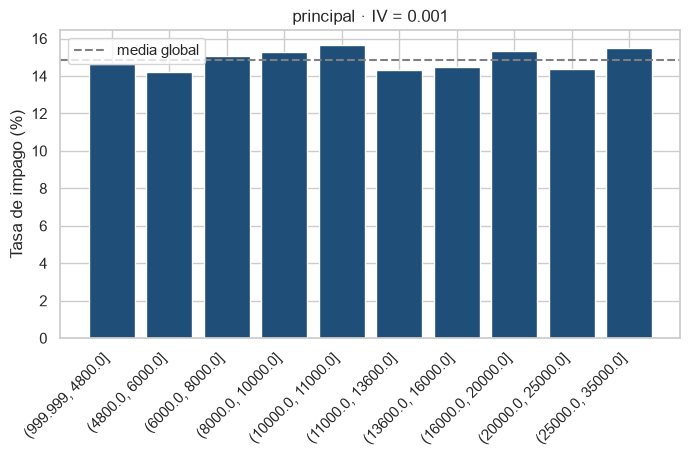

,n_prestamos,%_prestamos,tasa_impago,woe,iv
principal,,,,,
"(999.999, 4800.0]",46013,10.377,0.146,0.018,0.000
"(4800.0, 6000.0]",45637,10.292,0.142,0.052,0.000
"(6000.0, 8000.0]",52814,11.911,0.151,-0.017,0.000
"(8000.0, 10000.0]",65939,14.871,0.153,-0.035,0.000
"(10000.0, 11000.0]",11605,2.617,0.157,-0.063,0.000
"(11000.0, 13600.0]",44227,9.974,0.143,0.044,0.000
"(13600.0, 16000.0]",50609,11.414,0.145,0.029,0.000
"(16000.0, 20000.0]",50782,11.453,0.153,-0.038,0.000
"(20000.0, 25000.0]",37257,8.402,0.144,0.037,0.000


In [28]:
# Distribución, gráfico y tabla de riesgo por deciles del importe
analizar_numerica('principal')

**Qué se hace:** percentiles del importe y tasa de impago por decil.

**Qué se observa:** **sorprendentemente plana**: todos los deciles están entre el 14,2 % y el 15,7 % (IV ≈ 0,001). El importe por sí solo no dice nada del riesgo: 30.000 $ es mucho para quien gana 40.000 $ al año, pero poco para quien gana 200.000 $.

,count,mean,std,min,1%,25%,50%,75%,99%,max
ratio_principal_ingresos,443405.000,0.204,0.108,0.000,0.027,0.120,0.189,0.277,0.460,0.713


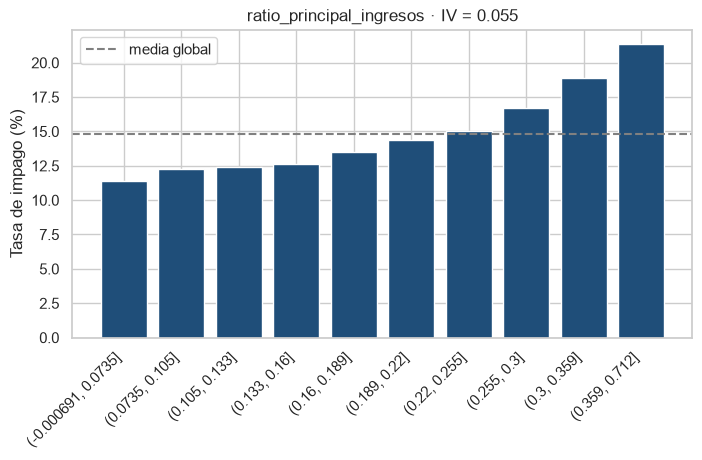

,n_prestamos,%_prestamos,tasa_impago,woe,iv
ratio_principal_ingresos,,,,,
"(-0.000691, 0.0735]",44460,10.027,0.114,0.305,0.008
"(0.0735, 0.105]",44339,10.000,0.123,0.219,0.004
"(0.105, 0.133]",45971,10.368,0.124,0.207,0.004
"(0.133, 0.16]",43129,9.727,0.127,0.185,0.003
"(0.16, 0.189]",44031,9.930,0.135,0.114,0.001
"(0.189, 0.22]",44114,9.949,0.144,0.036,0.000
"(0.22, 0.255]",44339,10.000,0.150,-0.015,0.000
"(0.255, 0.3]",46796,10.554,0.167,-0.140,0.002
"(0.3, 0.359]",41894,9.448,0.189,-0.291,0.009


In [29]:
# Importe en relación con los ingresos: qué parte de un año de ingresos supone el préstamo
ratio_principal_ingresos = (df['principal'] / df['ingresos']).rename('ratio_principal_ingresos')

# Se analiza la serie directamente (no se añade a df: la variable se crea en el notebook 04)
display(ratio_principal_ingresos.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).to_frame().T)
grafico_riesgo(ratio_principal_ingresos)
plt.show()
tabla_riesgo(ratio_principal_ingresos)

**Qué se hace:** se calcula el importe dividido entre los ingresos anuales (`ratio_principal_ingresos`) y se analiza igual que el resto de variables, **sin añadirlo todavía a los datos**.

**Qué se observa:** ahora sí hay señal, y fuerte: la relación es **monótona creciente**, del **11,4 %** (préstamo < 7 % de los ingresos anuales) al **21,3 %** (> 36 %). Su IV (≈ 0,055) es comparable al de los ingresos, y en la comprobación conjunta de la sección 11 es de las variables que **más** aportan.

> **Decisión D10 · Sacar `principal` del modelo de PD y sustituirlo por `ratio_principal_ingresos`, que se creará en el notebook 04.**
> - **Por qué:** el importe solo no separa el riesgo; lo que importa es el importe **en relación con la capacidad de pago**.
> - `principal` **se conserva en los datos**: hace falta para calcular el ratio y para los modelos de EAD y LGD (que se miden como fracción del importe).
> - **En la demo:** el formulario ya pide el importe y los ingresos; el ratio se calcula solo.

<a id="s7-4"></a>

### 7.4 · `fico` (D11)

**Variable analizada: `fico`** · punto medio del rango de puntuación FICO del cliente (creada en el notebook 02, D13). Va de 300 a 850; más alta = mejor historial.

,count,mean,std,min,1%,25%,50%,75%,99%,max
fico,443405.000,696.316,30.393,662.000,662.000,672.000,687.000,712.000,797.000,847.500


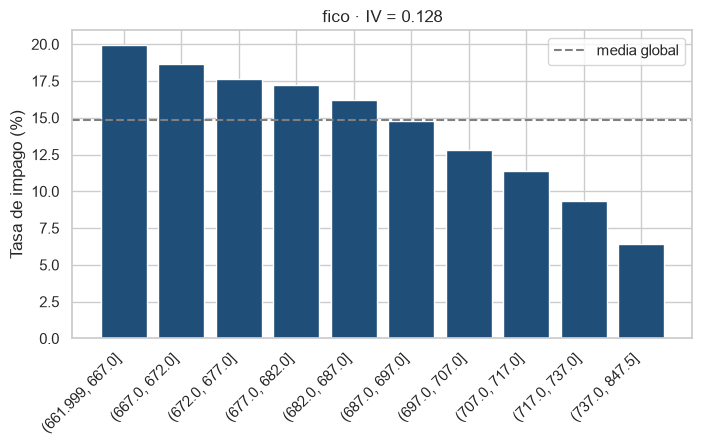

,n_prestamos,%_prestamos,tasa_impago,woe,iv
fico,,,,,
"(661.999, 667.0]",81079,18.286,0.199,-0.356,0.026
"(667.0, 672.0]",40457,9.124,0.186,-0.272,0.007
"(672.0, 677.0]",35875,8.091,0.176,-0.204,0.004
"(677.0, 682.0]",35348,7.972,0.172,-0.177,0.003
"(682.0, 687.0]",31038,7.000,0.162,-0.102,0.001
"(687.0, 697.0]",57091,12.876,0.147,0.008,0.000
"(697.0, 707.0]",45863,10.343,0.128,0.172,0.003
"(707.0, 717.0]",35084,7.912,0.114,0.306,0.007
"(717.0, 737.0]",40920,9.229,0.093,0.527,0.021


In [30]:
# Distribución, gráfico y tabla de riesgo por deciles de FICO
analizar_numerica('fico')

**Qué se hace:** percentiles del FICO y tasa de impago por decil.

**Qué se observa:**
- El mínimo es **662**: Lending Club no concedía préstamos por debajo de unos 660 puntos, así que los datos solo cubren a clientes con FICO aceptable. El modelo no sabrá nada de clientes con FICO más bajo (en la demo convendrá limitar el formulario a ese rango).
- La relación con el impago es **monótona decreciente** y la más fuerte de todas las candidatas: del **19,9 %** (FICO ≤ 667) al **6,4 %** (FICO > 737). IV ≈ 0,128 (poder medio).

> **Decisión D11 · Mantener `fico` sin cambios como variable candidata.**
> - **Por qué:** es la candidata más fuerte, con una relación perfectamente ordenada y sin valores extremos.
> - **Para la demo (notebook 08):** limitar el FICO del formulario al rango visto en entrenamiento (662–850).

<a id="s7-5"></a>

### 7.5 · Líneas de crédito (D12)

**Variables analizadas:**
- `num_lineas_credito`: nº de líneas de crédito **abiertas** (tarjetas, préstamos...).
- `num_lineas_credito_total`: nº **total** de líneas del historial, abiertas y cerradas.

,count,mean,std,min,1%,25%,50%,75%,99%,max
num_lineas_credito,443405.000,11.375,5.203,0.000,3.000,8.000,10.000,14.000,28.000,84.000


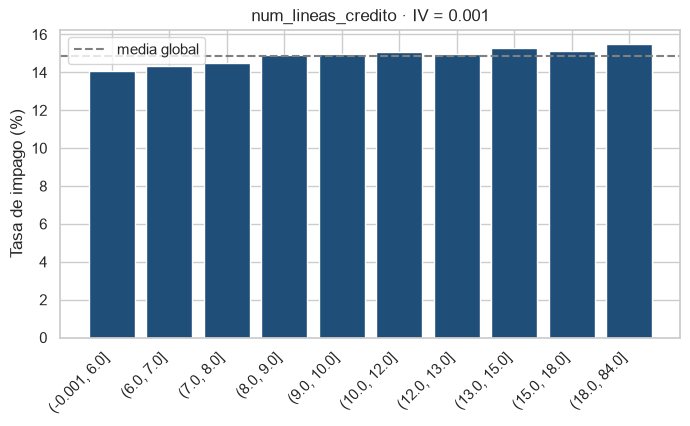

,n_prestamos,%_prestamos,tasa_impago,woe,iv
num_lineas_credito,,,,,
"(-0.001, 6.0]",68097,15.358,0.141,0.063,0.001
"(6.0, 7.0]",35107,7.918,0.143,0.040,0.000
"(7.0, 8.0]",39367,8.878,0.145,0.028,0.000
"(8.0, 9.0]",41023,9.252,0.149,-0.007,0.000
"(9.0, 10.0]",39598,8.930,0.150,-0.010,0.000
"(10.0, 12.0]",68498,15.448,0.151,-0.019,0.000
"(12.0, 13.0]",27749,6.258,0.150,-0.009,0.000
"(13.0, 15.0]",42745,9.640,0.153,-0.034,0.000
"(15.0, 18.0]",40192,9.064,0.151,-0.022,0.000


In [31]:
# Líneas abiertas
analizar_numerica('num_lineas_credito')

,count,mean,std,min,1%,25%,50%,75%,99%,max
num_lineas_credito_total,443405.000,24.773,11.718,2.000,6.000,16.000,23.000,31.000,60.000,156.000


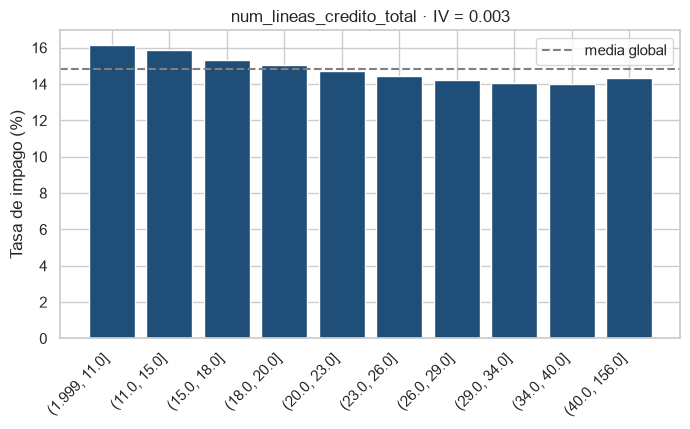

,n_prestamos,%_prestamos,tasa_impago,woe,iv
num_lineas_credito_total,,,,,
"(1.999, 11.0]",47619,10.739,0.161,-0.099,0.001
"(11.0, 15.0]",53137,11.984,0.159,-0.077,0.001
"(15.0, 18.0]",46978,10.595,0.153,-0.037,0.000
"(18.0, 20.0]",32212,7.265,0.150,-0.014,0.000
"(20.0, 23.0]",48102,10.848,0.147,0.008,0.000
"(23.0, 26.0]",44150,9.957,0.144,0.033,0.000
"(26.0, 29.0]",38360,8.651,0.142,0.052,0.000
"(29.0, 34.0]",49876,11.248,0.141,0.062,0.000
"(34.0, 40.0]",38808,8.752,0.140,0.069,0.000


In [32]:
# Líneas totales (abiertas y cerradas)
analizar_numerica('num_lineas_credito_total')

**Qué se hace:** percentiles y tasa de impago por decil de las dos variables.

**Qué se observa:**
- Las dos tienen **muy poca señal por sí solas** (IV ≈ 0,001 y 0,003). Las líneas abiertas suben ligeramente el impago (14,1 % → 15,5 %); las totales lo bajan ligeramente (16,1 % → 14,3 %).
- Están bastante relacionadas entre sí (correlación ≈ 0,68): quien tiene muchas líneas en total suele tener muchas abiertas.
- En la comprobación conjunta (sección 11), `num_lineas_credito` es la única de las dos que aporta algo junto al resto de variables: con el mismo saldo y uso de tarjetas, tener muchas líneas abiertas indica más dependencia del crédito.

> **Decisión D12 · Mantener `num_lineas_credito` como candidata y descartar `num_lineas_credito_total`.**
> - **Por qué:** la primera aporta algo en combinación con otras variables; la segunda está relacionada con ella y no aporta nada.
> - **Recorte:** el máximo de líneas abiertas es 84 (percentil 99: 28); se recortará en el notebook 04 si el modelo es lineal.

<a id="s7-6"></a>

### 7.6 · `num_hipotecas` (D13)

**Variable analizada: `num_hipotecas`** · nº de préstamos hipotecarios en el informe de crédito.

,count,mean,std,min,1%,25%,50%,75%,99%,max
num_hipotecas,443405.000,1.658,2.060,0.000,0.000,0.000,1.000,3.000,8.000,47.000


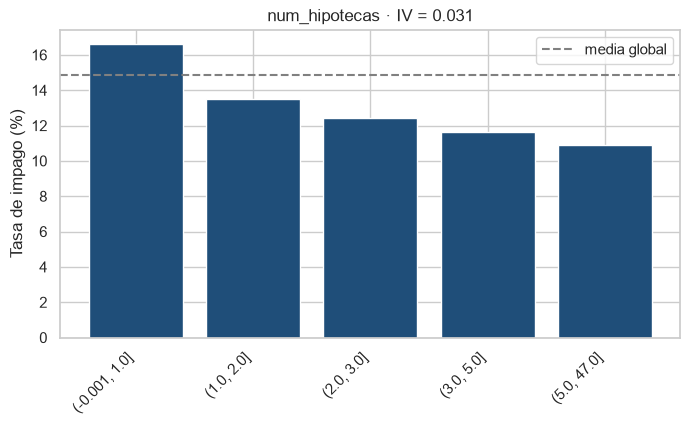

,n_prestamos,%_prestamos,tasa_impago,woe,iv
num_hipotecas,,,,,
"(-0.001, 1.0]",260975,58.857,0.166,-0.133,0.011
"(1.0, 2.0]",60851,13.724,0.135,0.112,0.002
"(2.0, 3.0]",44442,10.023,0.124,0.207,0.004
"(3.0, 5.0]",52038,11.736,0.116,0.282,0.008
"(5.0, 47.0]",25099,5.661,0.109,0.355,0.006


In [33]:
# Distribución, gráfico y tabla de riesgo de num_hipotecas
analizar_numerica('num_hipotecas')

**Qué se hace:** percentiles y tasa de impago por tramo (al haber muchos ceros y unos, los deciles se juntan en 5 tramos).

**Qué se observa:** relación **monótona decreciente**: del **16,6 %** (0–1 hipotecas) al **10,9 %** (más de 5). Tener hipotecas indica que algún banco ya concedió crédito al cliente y lo está pagando. El máximo (47) es extremo, pero el percentil 99 es 8.

In [34]:
# ¿Aporta algo más allá de la vivienda? Tasa de impago por vivienda y nº de hipotecas (3 = 3 o más)
impago.groupby([df['vivienda'], df['num_hipotecas'].clip(upper=3)]).mean().unstack()

num_hipotecas,0.000,1.000,2.000,3.000
vivienda,,,,
MORTGAGE,0.160,0.137,0.129,0.111
OWN,0.174,0.147,0.133,0.125
RENT,0.175,0.177,0.161,0.154


**Qué se hace:** tasa de impago por tipo de vivienda (filas) y nº de hipotecas (columnas, con 3 o más juntas).

**Qué se observa:** dentro de cada tipo de vivienda, más hipotecas sigue significando menos impago (en `MORTGAGE`: 16,0 % con 0 hipotecas frente a 11,1 % con 3 o más). `num_hipotecas` y `vivienda` están relacionadas, pero cada una aporta información propia.

> **Decisión D13 · Mantener `num_hipotecas` como variable candidata y recortarla en el notebook 04.**
> - **Por qué:** IV ≈ 0,031, relación ordenada y señal propia aunque se conozca la vivienda.
> - **Recorte:** al percentil 99 de entrenamiento (8) si el modelo es lineal, para que los pocos casos extremos no pesen de más.

<a id="s7-7"></a>

### 7.7 · `saldo_revolving` (D14)

**Variable analizada: `saldo_revolving`** · deuda pendiente en crédito *revolving* ($): tarjetas y líneas de crédito que se usan, se devuelven y se vuelven a usar.

,count,mean,std,min,1%,25%,50%,75%,99%,max
saldo_revolving,443405.000,15932.754,21444.192,0.000,413.000,6086.000,11077.000,19439.000,89095.360,2904836.000


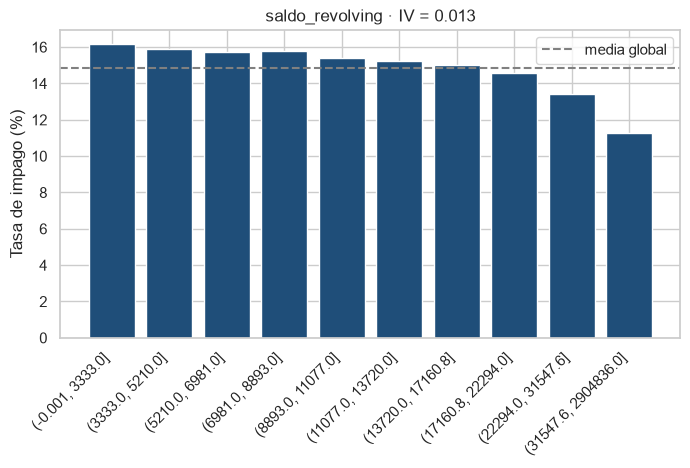

,n_prestamos,%_prestamos,tasa_impago,woe,iv
saldo_revolving,,,,,
"(-0.001, 3333.0]",44353,10.003,0.161,-0.099,0.001
"(3333.0, 5210.0]",44331,9.998,0.159,-0.079,0.001
"(5210.0, 6981.0]",44339,10.000,0.157,-0.068,0.000
"(6981.0, 8893.0]",44348,10.002,0.158,-0.072,0.001
"(8893.0, 11077.0]",44352,10.003,0.154,-0.042,0.000
"(11077.0, 13720.0]",44325,9.997,0.152,-0.031,0.000
"(13720.0, 17160.8]",44335,9.999,0.150,-0.014,0.000
"(17160.8, 22294.0]",44348,10.002,0.146,0.020,0.000
"(22294.0, 31547.6]",44333,9.998,0.134,0.117,0.001


In [35]:
# Distribución, gráfico y tabla de riesgo por deciles del saldo revolving
analizar_numerica('saldo_revolving')

**Qué se hace:** percentiles del saldo y tasa de impago por decil.

**Qué se observa:**
- Distribución muy **asimétrica** (mediana 11.000 $, percentil 99 de 89.000 $, máximo 2,9 millones).
- Relación **decreciente**, sobre todo en los deciles altos: del **16,1 %** (≤ 3.300 $) al **11,3 %** (> 31.500 $). Puede parecer contraintuitivo (más deuda, menos impago), pero un saldo alto suele ir con **límites de crédito altos**, que los bancos solo conceden a clientes solventes. Está relacionado con los ingresos (correlación ≈ 0,42).

> **Decisión D14 · Mantener `saldo_revolving` como variable candidata y aplicarle el logaritmo en el notebook 04.**
> - **Por qué:** su IV es bajo (≈ 0,013), pero en la comprobación conjunta (sección 11) aporta algo más allá de los ingresos y el uso de tarjetas.
> - **Logaritmo:** por la fuerte asimetría, igual que los ingresos.

<a id="s7-8"></a>

### 7.8 · Porcentajes de uso del crédito (D15)

**Variables analizadas:**
- `porc_uso_revolving`: % del límite *revolving* total que está usando.
- `porc_uso_tarjetas`: % del límite de sus **tarjetas bancarias** que está usando.
- `porc_tarjetas_75p`: % de sus tarjetas bancarias que superan el 75 % de su límite.

,count,mean,std,min,1%,25%,50%,75%,99%,max
porc_uso_revolving,443405.000,54.540,23.607,0.000,2.900,37.200,55.200,72.800,98.100,892.300


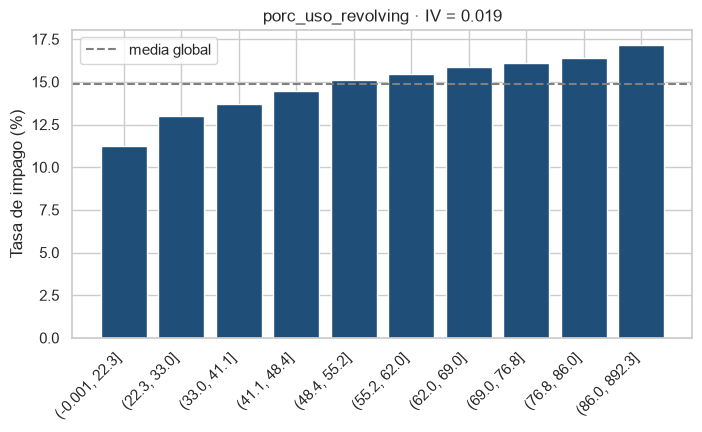

,n_prestamos,%_prestamos,tasa_impago,woe,iv
porc_uso_revolving,,,,,
"(-0.001, 22.3]",44550,10.047,0.112,0.319,0.009
"(22.3, 33.0]",44651,10.070,0.130,0.155,0.002
"(33.0, 41.1]",44061,9.937,0.137,0.093,0.001
"(41.1, 48.4]",44310,9.993,0.144,0.032,0.000
"(48.4, 55.2]",44412,10.016,0.151,-0.021,0.000
"(55.2, 62.0]",44801,10.104,0.155,-0.050,0.000
"(62.0, 69.0]",43734,9.863,0.159,-0.078,0.001
"(69.0, 76.8]",44454,10.026,0.161,-0.094,0.001
"(76.8, 86.0]",44122,9.951,0.164,-0.118,0.001


In [36]:
# Uso del límite revolving total
analizar_numerica('porc_uso_revolving')

,count,mean,std,min,1%,25%,50%,75%,99%,max
porc_uso_tarjetas,443405.000,63.130,27.118,0.000,0.200,43.300,67.300,86.800,101.000,318.200


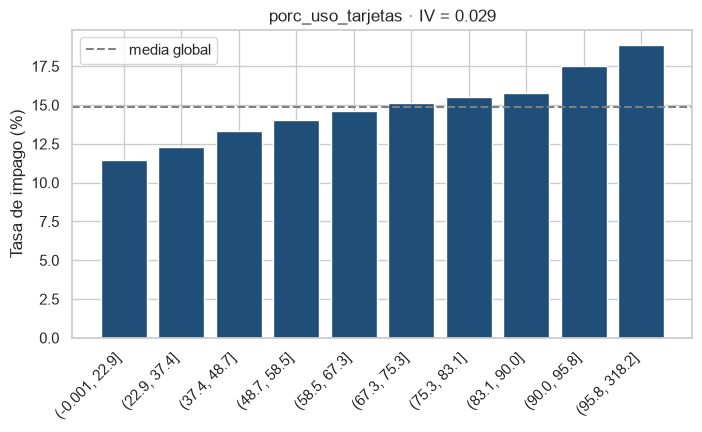

,n_prestamos,%_prestamos,tasa_impago,woe,iv
porc_uso_tarjetas,,,,,
"(-0.001, 22.9]",44403,10.014,0.115,0.295,0.008
"(22.9, 37.4]",44407,10.015,0.123,0.220,0.004
"(37.4, 48.7]",44543,10.046,0.133,0.128,0.002
"(48.7, 58.5]",44365,10.006,0.140,0.068,0.000
"(58.5, 67.3]",44175,9.963,0.146,0.021,0.000
"(67.3, 75.3]",44253,9.980,0.151,-0.022,0.000
"(75.3, 83.1]",44648,10.069,0.155,-0.053,0.000
"(83.1, 90.0]",44054,9.935,0.158,-0.074,0.001
"(90.0, 95.8]",44790,10.101,0.175,-0.196,0.004


In [37]:
# Uso del límite de las tarjetas bancarias
analizar_numerica('porc_uso_tarjetas')

,count,mean,std,min,1%,25%,50%,75%,99%,max
porc_tarjetas_75p,443405.000,48.818,35.473,0.000,0.000,20.000,50.000,77.800,100.000,100.000


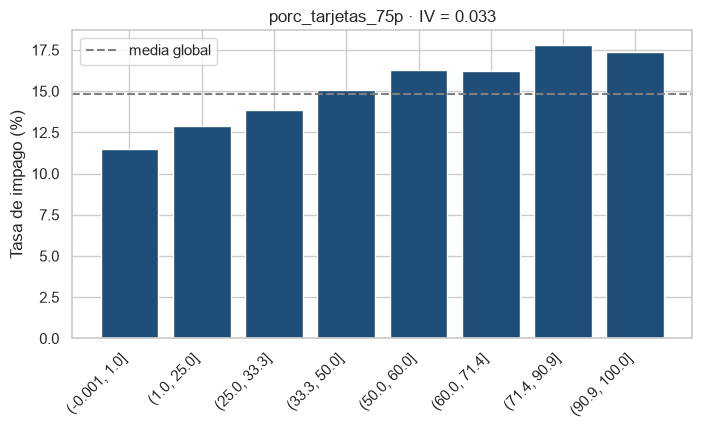

,n_prestamos,%_prestamos,tasa_impago,woe,iv
porc_tarjetas_75p,,,,,
"(-0.001, 1.0]",88695,20.003,0.115,0.295,0.016
"(1.0, 25.0]",55867,12.600,0.129,0.165,0.003
"(25.0, 33.3]",36847,8.310,0.139,0.079,0.000
"(33.3, 50.0]",74577,16.819,0.150,-0.015,0.000
"(50.0, 60.0]",17635,3.977,0.163,-0.111,0.001
"(60.0, 71.4]",39145,8.828,0.162,-0.106,0.001
"(71.4, 90.9]",42086,9.492,0.178,-0.216,0.005
"(90.9, 100.0]",88553,19.971,0.174,-0.188,0.008


In [38]:
# % de tarjetas por encima del 75 % de su límite
analizar_numerica('porc_tarjetas_75p')

**Qué se hace:** percentiles y tasa de impago por decil de las tres variables de uso del crédito.

**Qué se observa:** las tres tienen una relación **monótona creciente** con el impago (cuanto más cerca del límite, más impago): `porc_uso_tarjetas` va del **11,5 %** al **18,9 %**, `porc_tarjetas_75p` del 11,5 % al 17,4 % y `porc_uso_revolving` del 11,2 % al 17,2 %. Las tres son débiles (IV 0,019–0,033).

In [39]:
# Correlación de Spearman entre las tres (mide si se mueven juntas, aunque no sea en línea recta)
df[['porc_uso_revolving', 'porc_uso_tarjetas', 'porc_tarjetas_75p']].corr(method='spearman')

,porc_uso_revolving,porc_uso_tarjetas,porc_tarjetas_75p
porc_uso_revolving,1.000,0.825,0.712
porc_uso_tarjetas,0.825,1.000,0.863
porc_tarjetas_75p,0.712,0.863,1.000


**Qué se hace:** correlación de **Spearman** entre las tres variables. Se usa Spearman en lugar de Pearson porque compara el **orden** de los valores: no le afectan los extremos ni exige una relación en línea recta. Va de −1 a 1; por encima de 0,7 se considera alta.

**Qué se observa:** las tres miden prácticamente lo mismo: **0,86** entre uso de tarjetas y tarjetas por encima del 75 %, **0,83** entre uso de tarjetas y uso revolving y 0,71 entre las otras dos. Además, en el notebook 02 (D5) los nulos de las dos de tarjetas se imputaron a partir de `porc_uso_revolving`.

> **Decisión D15 · Quedarse solo con `porc_uso_tarjetas`; descartar `porc_uso_revolving` y `porc_tarjetas_75p`.**
> - **Por qué una sola:** las tres están muy correlacionadas; meterlas juntas no mejora el modelo (sección 11) y hace inestables sus coeficientes en una regresión logística.
> - **Por qué esta:** es la más fácil de entender y de preguntar en la demo ("¿qué % del límite de tus tarjetas usas?"), con un IV casi igual al de `porc_tarjetas_75p` (0,029 frente a 0,033).
> - **Recorte:** valores por encima del 100 % son reales (D19 del notebook 02); se recortarán en el notebook 04 si el modelo es lineal.

<a id="s7-9"></a>

### 7.9 · `num_consultas_6meses` (D16)

**Variable analizada: `num_consultas_6meses`** · nº de consultas a su historial de crédito en los últimos 6 meses. Cada nueva solicitud de crédito genera una.

,count,mean,std,min,1%,25%,50%,75%,99%,max
num_consultas_6meses,443405.000,0.691,0.971,0.000,0.000,0.000,0.000,1.000,4.000,8.000


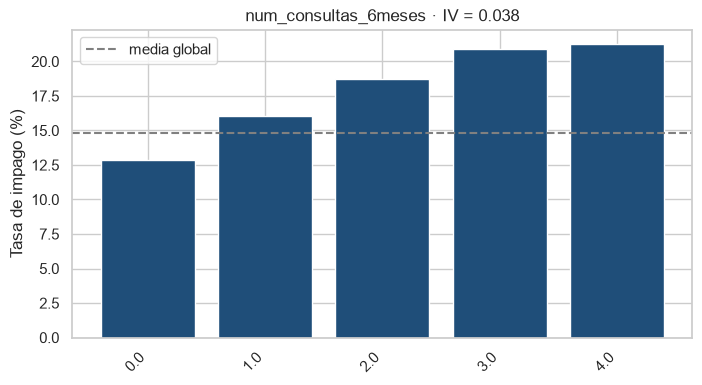

,n_prestamos,%_prestamos,tasa_impago,woe,iv
num_consultas_6meses,,,,,
0.0,247735,55.871,0.129,0.166,0.015
1.0,121591,27.422,0.160,-0.091,0.002
2.0,47659,10.748,0.187,-0.278,0.009
3.0,18881,4.258,0.209,-0.416,0.008
4.0,7539,1.700,0.212,-0.437,0.004


In [40]:
# Percentiles y tabla de riesgo con los valores altos agrupados (4 = 4 o más consultas)
display(percentiles('num_consultas_6meses'))
consultas_tope = df['num_consultas_6meses'].clip(upper=4)
grafico_riesgo(consultas_tope)
plt.show()
tabla_riesgo(consultas_tope)

**Qué se hace:** percentiles y tasa de impago por nº de consultas, con 4 o más juntas (solo el 1,7 % de los préstamos tiene 4 o más).

**Qué se observa:** relación **monótona creciente**: **12,9 %** sin consultas, 16,0 % con una, 18,7 % con dos y **21 %** con tres o más. Buscar crédito en varios sitios a la vez es una señal clásica de necesidad de liquidez.

> **Decisión D16 · Mantener `num_consultas_6meses` como variable candidata, recortada en 4 en el notebook 04.**
> - **Por qué:** IV ≈ 0,038 y relación ordenada. A partir de 3–4 consultas la tasa deja de subir y hay muy pocos casos, así que se agrupan.

<a id="s7-10"></a>

### 7.10 · Incidencias del historial (D17)

**Variables analizadas:**
- `num_retrasos_2anios`: nº de retrasos de más de 30 días en los últimos 2 años.
- `num_derogatorios`: nº de registros públicos negativos (sentencias, embargos, quiebras...).
- `num_quiebras`: nº de quiebras en registros públicos.
- `num_cancelaciones_12meses`: nº de deudas que un acreedor dio por perdidas en los últimos 12 meses.

In [41]:
# Las cuatro son recuentos con casi todo ceros: se compara "sin incidencias" (0) frente a "alguna" (1 o más)
INCIDENCIAS = ['num_retrasos_2anios', 'num_derogatorios', 'num_quiebras', 'num_cancelaciones_12meses']

resumen_incidencias = pd.DataFrame({
    '%_con_alguna': [(df[v] > 0).mean() * 100 for v in INCIDENCIAS],                 # % de préstamos con 1 o más
    'impago_sin': [impago[df[v] == 0].mean() for v in INCIDENCIAS],                  # tasa con 0 incidencias
    'impago_con': [impago[df[v] > 0].mean() for v in INCIDENCIAS],                   # tasa con 1 o más
    'iv': [tabla_riesgo((df[v] > 0).rename(v))['iv'].sum() for v in INCIDENCIAS],   # IV de la versión 0 / 1+
}, index=INCIDENCIAS)
resumen_incidencias

,%_con_alguna,impago_sin,impago_con,iv
num_retrasos_2anios,19.309,0.147,0.156,0.001
num_derogatorios,15.977,0.145,0.167,0.004
num_quiebras,11.664,0.146,0.169,0.003
num_cancelaciones_12meses,0.809,0.148,0.153,0.000


**Qué se hace:** para cada variable de incidencias, el % de préstamos con alguna, la tasa de impago sin y con incidencias, y el IV de esa versión 0 / 1 o más.

**Qué se observa:** las diferencias son **mínimas** (por ejemplo, 14,7 % sin retrasos frente a 15,6 % con alguno) y todos los IV están muy por debajo de 0,02. Las cancelaciones apenas existen (0,8 % de los préstamos). Como con `tramo_ult_retraso` (6.6), lo más probable es que Lending Club ya filtrara a los clientes con incidencias graves, y entre los aceptados estas variables no distinguen el riesgo.

In [42]:
# Derogatorios y quiebras: ¿miden lo mismo? (una quiebra es un tipo de registro público negativo)
pd.crosstab(df['num_derogatorios'].clip(upper=2), df['num_quiebras'].clip(upper=2))

num_quiebras,0.000,1.000,2.000
num_derogatorios,,,
0.000,372562,0,0
1.000,13735,45312,0
2.000,5388,3304,3104


**Qué se hace:** tabla cruzada del nº de derogatorios y del nº de quiebras (2 = 2 o más).

**Qué se observa:** la mayoría de los derogatorios son quiebras (correlación de Spearman ≈ 0,83): son casi la misma variable.

> **Decisión D17 · Descartar las cuatro variables de incidencias: `num_retrasos_2anios`, `num_derogatorios`, `num_quiebras` y `num_cancelaciones_12meses`.**
> - **Por qué:** no separan el riesgo ni solas ni en combinación con el resto (sección 11). Derogatorios y quiebras, además, son casi la misma variable.
> - **En la demo:** son 4 preguntas menos en el formulario.

<a id="s7-11"></a>

### 7.11 · Antigüedad del historial de crédito (D18)

**Variable analizada (nueva): `antiguedad_historial`** · años entre el primer crédito del cliente (`fecha_primer_credito`) y la concesión del préstamo (`fecha_concesion`). Se creará en el notebook 04; aquí solo se comprueba si tiene señal.

,count,mean,std,min,1%,25%,50%,75%,99%,max
antiguedad_historial,443405.000,16.225,7.537,2.998,3.923,11.086,14.746,20.000,39.669,71.001


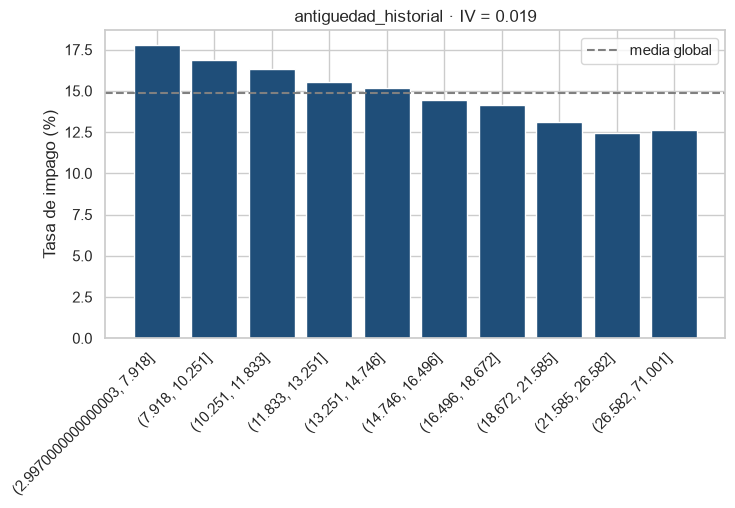

,n_prestamos,%_prestamos,tasa_impago,woe,iv
antiguedad_historial,,,,,
"(2.9970000000000003, 7.918]",44433,10.021,0.178,-0.216,0.005
"(7.918, 10.251]",44586,10.055,0.169,-0.151,0.002
"(10.251, 11.833]",44433,10.021,0.163,-0.110,0.001
"(11.833, 13.251]",44650,10.070,0.155,-0.053,0.000
"(13.251, 14.746]",44118,9.950,0.152,-0.026,0.000
"(14.746, 16.496]",44123,9.951,0.145,0.032,0.000
"(16.496, 18.672]",44155,9.958,0.141,0.057,0.000
"(18.672, 21.585]",44413,10.016,0.131,0.142,0.002
"(21.585, 26.582]",44246,9.979,0.124,0.205,0.004


In [43]:
# Años de historial de crédito al pedir el préstamo (365,25 días por año para contar los bisiestos)
antiguedad_historial = ((df['fecha_concesion'] - df['fecha_primer_credito']).dt.days / 365.25).rename('antiguedad_historial')

# Se analiza la serie directamente, sin añadirla a df
display(antiguedad_historial.describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]).to_frame().T)
grafico_riesgo(antiguedad_historial)
plt.show()
tabla_riesgo(antiguedad_historial)

**Qué se hace:** se calcula la antigüedad del historial en años y se analiza igual que el resto, **sin añadirla todavía a los datos**.

**Qué se observa:** la mediana es de unos 15 años (mínimo 3, máximo 71). Relación **decreciente**: del **17,8 %** (menos de 8 años de historial) al 12,4–12,6 % (más de 21 años). IV ≈ 0,019, en el límite de lo débil.

> **Decisión D18 · Crear `antiguedad_historial` en el notebook 04 como variable candidata (y no usar las fechas directamente).**
> - **Por qué:** una fecha no sirve como variable de un modelo; la **duración** del historial sí, y tiene una relación ordenada con el impago.
> - **En la demo:** se preguntará "¿cuántos años hace que tuviste tu primer crédito?".

<a id="s8"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">8 · REDUNDANCIA ENTRE VARIABLES (D19)</span>

</div>

Dos variables muy correlacionadas aportan casi la misma información: en una regresión logística sus coeficientes se vuelven inestables y el modelo es más difícil de interpretar. Aquí se revisan las correlaciones de todas las variables numéricas **que siguen siendo candidatas** tras las decisiones anteriores (incluidas las dos que se crearán en el notebook 04).

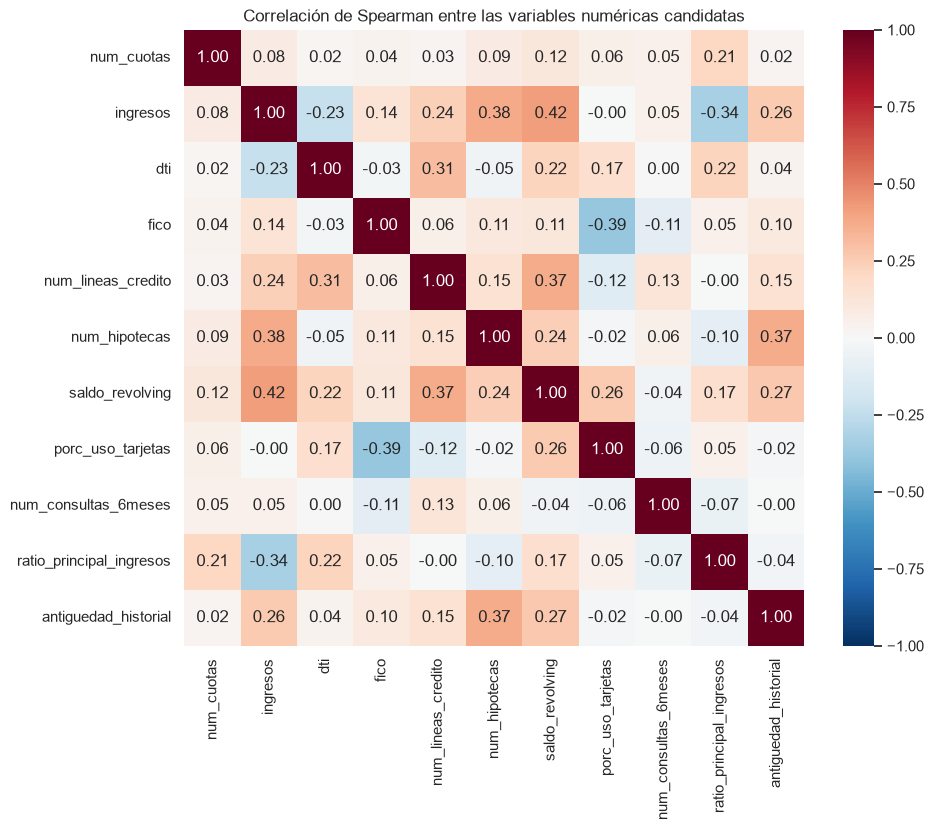

,,spearman
ingresos,saldo_revolving,0.417


In [44]:
# Variables numéricas candidatas tras las decisiones D8–D18 (más las dos que se crean en el notebook 04)
NUMERICAS_CANDIDATAS = ['num_cuotas', 'ingresos', 'dti', 'fico', 'num_lineas_credito', 'num_hipotecas',
                        'saldo_revolving', 'porc_uso_tarjetas', 'num_consultas_6meses']
tabla_numericas = df[NUMERICAS_CANDIDATAS].join([ratio_principal_ingresos, antiguedad_historial])

# Matriz de correlación de Spearman y mapa de calor
correlaciones = tabla_numericas.corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(correlaciones, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax)  # rojo = positiva, azul = negativa
ax.set_title('Correlación de Spearman entre las variables numéricas candidatas')
plt.show()

# Pares con correlación alta (en valor absoluto), ordenados de mayor a menor
triangulo = correlaciones.where(np.triu(np.ones(correlaciones.shape, dtype=bool), k=1))  # cada par una sola vez
pares = triangulo.stack().rename('spearman')
pares[pares.abs() >= 0.4].sort_values(key=abs, ascending=False).to_frame()

**Qué se hace:** matriz de correlación de Spearman entre las 11 variables numéricas candidatas y lista de los pares con correlación de 0,4 o más (en valor absoluto).

**Qué se observa:** tras quitar los porcentajes de uso redundantes (D15) y las incidencias (D17), **ningún par supera 0,7**. El único par por encima de 0,4 es ingresos con saldo revolving (≈ 0,42): una relación moderada y esperable (más ingresos, más límite de crédito) que no impide usar ambas variables.

In [45]:
# Categóricas: antigüedad_empleo y sector_empleo comparten la categoría 'sin_empleo_declarado'
pd.crosstab(df['antigüedad_empleo'] == 'sin_empleo_declarado',
            df['sector_empleo'] == 'sin_empleo_declarado',
            rownames=['antigüedad: sin empleo'], colnames=['sector: sin empleo'])

sector: sin empleo,False,True
antigüedad: sin empleo,,
False,414466,3620
True,197,25122


**Qué se hace:** tabla cruzada de los préstamos marcados como `sin_empleo_declarado` en cada una de las dos variables de empleo.

**Qué se observa:** coinciden casi siempre (unos 25.000 préstamos en las dos; unos 3.600 solo en `sector_empleo`, que también marca así los puestos vacíos). Es decir, el grupo de más riesgo de `antigüedad_empleo` ya está recogido por `sector_empleo`. Fuera de ese grupo, la antigüedad aporta muy poco (sección 11).

> **Decisión D19 · No eliminar más variables por redundancia.**
> - **Por qué:** entre las candidatas numéricas no queda ningún par con correlación alta (> 0,7).
> - **Pendiente para el notebook 05:** `antigüedad_empleo` y `sector_empleo` comparten el grupo `sin_empleo_declarado`. Se mantienen las dos y la regularización del modelo (L1) decidirá si `antigüedad_empleo` sobra.

<a id="s9"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">9 · ESTABILIDAD EN EL TIEMPO (D20)</span>

</div>

Los préstamos de entrenamiento se concedieron entre 2012 y 2015, pero el modelo se usará con clientes nuevos. Una variable solo es fiable si su **relación con el impago** y su **distribución** se mantienen a lo largo del tiempo. Si una variable funciona en un año y en otro no, el modelo aprendería algo que no se repetirá.

Se revisan dos cosas para cada variable candidata:
1. **El IV de cada año**: ¿separa el riesgo todos los años?
2. **El PSI** (explicado en la sección [4.2](#s4-2)): ¿ha cambiado su distribución? Se calcula como el IV, pero comparando el reparto de los préstamos entre los tramos en dos periodos:

$$\text{PSI} = \sum_{\text{tramos}} (\%\ \text{actual} - \%\ \text{referencia}) \times \ln\left(\frac{\%\ \text{actual}}{\%\ \text{referencia}}\right)$$

Escala habitual: < 0,1 estable · 0,1–0,25 cambio moderado · > 0,25 cambio importante. Aquí se compara el último año (2015) con los dos primeros (2012–2013).

In [46]:
# Tabla con las candidatas (incluidas las dos que se crean en el notebook 04)
datos_estabilidad = df.join([ratio_principal_ingresos, antiguedad_historial])
VARIABLES_ESTABILIDAD = ['antigüedad_empleo', 'vivienda', 'finalidad', 'sector_empleo', 'num_cuotas',
                         'ingresos', 'dti', 'fico', 'num_lineas_credito', 'num_hipotecas', 'saldo_revolving',
                         'porc_uso_tarjetas', 'num_consultas_6meses', 'ratio_principal_ingresos', 'antiguedad_historial']

def tramos_fijos(variable, n_tramos=10):
    '''Tramos con los MISMOS cortes para todos los años (deciles de todo el entrenamiento).'''
    serie = datos_estabilidad[variable]
    if variable == 'num_consultas_6meses':
        return serie.clip(upper=4)                                    # 4 = 4 o más (D16)
    if pd.api.types.is_numeric_dtype(serie) and serie.nunique() > 12:
        cortes = np.unique(serie.quantile(np.linspace(0, 1, n_tramos + 1)))
        cortes[0], cortes[-1] = -np.inf, np.inf                       # que entre cualquier valor futuro
        return pd.cut(serie, cortes)
    return serie                                                      # categóricas: tal cual

# La función psi() está definida en la sección 4.2

# IV de cada año y PSI (2015 frente a 2012-2013) de cada variable
filas = {}
for v in VARIABLES_ESTABILIDAD:
    tramos = tramos_fijos(v)
    fila = {a: tabla_riesgo(tramos[anio == a])['iv'].sum() for a in [2012, 2013, 2014, 2015]}
    fila['psi_2015_vs_2012-13'] = psi(tramos[anio.isin([2012, 2013])], tramos[anio == 2015])
    filas[v] = fila
estabilidad = pd.DataFrame(filas).T
estabilidad

,2012,2013,2014,2015,psi_2015_vs_2012-13
antigüedad_empleo,0.003,0.004,0.020,0.021,0.018
vivienda,0.006,0.018,0.046,0.044,0.019
finalidad,0.042,0.025,0.023,0.023,0.013
sector_empleo,0.011,0.016,0.050,0.049,0.988
num_cuotas,0.135,0.161,0.000,0.000,1.890
ingresos,0.040,0.046,0.081,0.058,0.012
dti,0.031,0.053,0.050,0.058,0.044
fico,0.125,0.095,0.137,0.154,0.037
num_lineas_credito,0.005,0.002,0.001,0.002,0.024
num_hipotecas,0.011,0.019,0.040,0.041,0.013


**Qué se hace:** para cada variable candidata se calcula su IV en cada año de concesión (con los mismos tramos todos los años) y su PSI entre 2012–2013 y 2015.

**Qué se observa:**
- **La distribución de casi todas es estable:** PSI por debajo de 0,1. `fico`, `dti`, `ingresos`, `finalidad` y `porc_uso_tarjetas` separan además el riesgo de forma parecida todos los años.
- Varias variables (`vivienda`, `num_hipotecas`, `antigüedad_empleo`, `saldo_revolving`, `antiguedad_historial`) separan **menos en 2012–2013**. En esos años los préstamos a 60 cuotas concentran buena parte del riesgo y reducen el peso relativo del resto. Si se comparan solo los préstamos a 36 cuotas, la diferencia entre años se reduce (por ejemplo, `vivienda`: IV ≈ 0,02–0,04 en 2012–2013 frente a ≈ 0,045 después). No es un problema de estabilidad, sino de mezcla de plazos.
- **`num_cuotas`** tiene IV 0 en 2014–2015 y un PSI enorme, pero es esperado: en esos años **todos** los préstamos son a 36 cuotas (D5 del notebook 01).
- **`ratio_principal_ingresos`** separa más en 2012–2013 (IV ≈ 0,12) que en 2014–2015 (≈ 0,03–0,04). En parte es por el plazo: los préstamos a 60 cuotas son más grandes en relación con los ingresos y tienen más impago. Aun así, mantiene un IV débil pero claro los cuatro años.
- **`sector_empleo` tiene un PSI de ≈ 1**, un cambio enorme en su distribución. Además, su IV pasa de ≈ 0,01 en 2012–2013 a ≈ 0,05 en 2014–2015. Se analiza abajo.

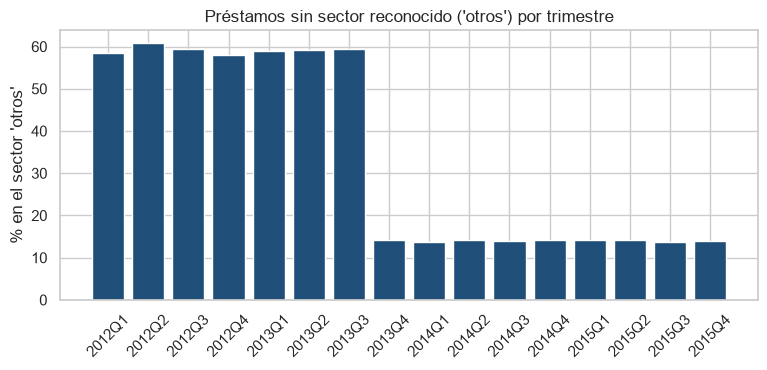

In [47]:
# % de préstamos en el sector 'otros' por trimestre de concesión
trimestre = df['fecha_concesion'].dt.to_period('Q')
pct_otros = (df['sector_empleo'] == 'otros').groupby(trimestre).mean() * 100

fig, ax = plt.subplots(figsize=(9, 3.5))
ax.bar(pct_otros.index.astype(str), pct_otros.values, color='#1f4e79')
ax.set_ylabel("% en el sector 'otros'")
ax.set_title("Préstamos sin sector reconocido ('otros') por trimestre")
ax.tick_params(axis='x', rotation=45)
plt.show()

**Qué se hace:** % de préstamos clasificados en el sector `otros` en cada trimestre de concesión.

**Qué se observa:** un **salto brusco a finales de 2013**: hasta el tercer trimestre de 2013 alrededor del **59 %** de los préstamos caen en `otros`, y desde el cuarto trimestre solo el **14 %**. La explicación más probable (inferida de los datos) es que **Lending Club cambió lo que pedía en el campo del empleo**: antes se guardaba el **nombre de la empresa** (que las reglas de palabras clave del notebook 02 no saben clasificar) y después el **puesto de trabajo**. Por eso el sector solo es informativo para unos 3 de cada 4 préstamos de entrenamiento.

> **Decisión D20 · Mantener las candidatas; `sector_empleo` se mantiene con cautela.**
> - **Por qué:** todas las variables son estables salvo dos casos explicados: `num_cuotas` (no hay préstamos a 60 cuotas después de 2013) y `sector_empleo` (cambio en cómo se recogía el empleo a finales de 2013).
> - **`sector_empleo`:** desde finales de 2013 refleja el puesto de trabajo, igual que lo que pedirá la demo. Antes, el sector `otros` mezcla puestos sin clasificar con nombres de empresa. Se mantiene porque los datos recientes son los más parecidos a los de la demo, pero el modelo aprenderá su efecto sobre todo de 2014–2015. Esto refuerza la comparación con y sin esta variable del notebook 05 (D5).
> - **`num_cuotas`:** el efecto de las 60 cuotas solo se aprende con préstamos de 2012–2013. En la demo convendrá advertirlo.

<a id="s10"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">10 · PRIMER VISTAZO A EAD Y LGD (D21)</span>

</div>

Hasta aquí el análisis se ha centrado en la **PD** (¿impagará?). Los otros dos modelos solo se aplican a los préstamos **impagados**:
- **EAD** (*Exposure at Default*): qué fracción del importe quedaba por devolver en el momento del impago = (principal − importe amortizado) / principal.
- **LGD** (*Loss Given Default*): qué fracción de esa deuda pendiente se pierde = 1 − importe recuperado / deuda pendiente, limitada a 0–1 (D24 del notebook 02).

Los objetivos definitivos se construyen en el notebook 04. Aquí solo se calculan para ver su forma y si alguna variable candidata se relaciona con ellos.

In [48]:
# Solo los préstamos impagados
impagados = datos_estabilidad[impago == 1]

# EAD: fracción del importe pendiente de devolver al impagar
pendiente = impagados['principal'] - impagados['imp_amortizado']
ead = (pendiente / impagados['principal']).rename('ead')

# LGD: fracción de la deuda pendiente que no se recupera (0–1); sin deuda pendiente no se puede calcular
lgd = (1 - impagados['imp_recuperado'] / pendiente).where(pendiente > 0).clip(0, 1).rename('lgd')

print(f"Préstamos impagados: {len(impagados):,}")
pd.concat([ead, lgd], axis=1).describe(percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]).T

Préstamos impagados: 65,838


,count,mean,std,min,1%,10%,25%,50%,75%,90%,99%,max
ead,65838.000,0.593,0.241,0.000,0.062,0.237,0.417,0.624,0.790,0.890,0.979,1.000
lgd,65836.000,0.869,0.148,0.000,0.323,0.759,0.848,0.895,0.999,1.000,1.000,1.000


**Qué se hace:** se calculan, para los 65.838 préstamos impagados, una versión preliminar de la EAD y de la LGD, y se resumen sus distribuciones.

**Qué se observa:**
- **EAD:** de media quedaba por devolver el **59 %** del importe (mediana 62 %). Está muy repartida: hay impagos casi al principio (EAD cercana a 1) y otros casi al final (cercana a 0).
- **LGD:** muy alta. De media se pierde el **87 %** de la deuda pendiente (mediana 90 %). En una cuarta parte de los impagos se pierde todo. Son préstamos sin garantía (no hay casa ni coche que embargar).

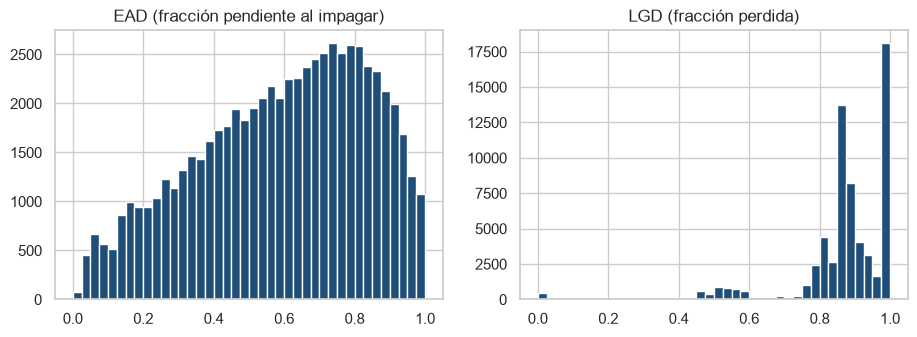

,%_sin_recuperacion
fecha_concesion,
2012,0.022
2013,0.084
2014,0.245
2015,0.279


In [49]:
# Histogramas de EAD y LGD
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
ejes[0].hist(ead, bins=40, color='#1f4e79')
ejes[0].set_title('EAD (fracción pendiente al impagar)')
ejes[1].hist(lgd.dropna(), bins=40, color='#1f4e79')
ejes[1].set_title('LGD (fracción perdida)')
plt.show()

# % de impagados SIN ninguna recuperación por año de concesión
(impagados['imp_recuperado'] == 0).groupby(anio[impago == 1]).mean().rename('%_sin_recuperacion').to_frame()

**Qué se hace:** histogramas de las dos variables y % de impagados sin ningún importe recuperado según el año de concesión.

**Qué se observa:**
- La LGD se concentra entre 0,8 y 1, con un pico en 1 (pérdida total).
- Los impagados **sin ninguna recuperación** pasan del **2 %** en 2012 al **28 %** en 2015. Es poco probable que el riesgo cambiara tanto. La hipótesis más razonable es que en la fecha de corte del dataset (finales de 2018) las recuperaciones de los impagos más recientes **aún no habían terminado**, o que esa deuda se vendió a agencias de cobro. Si es así, la LGD de 2014–2015 está **sobrestimada**.

In [50]:
# Correlación de Spearman de cada candidata numérica con EAD y LGD (solo impagados)
numericas_ead_lgd = ['num_cuotas', 'principal', 'ingresos', 'dti', 'fico', 'num_lineas_credito', 'num_hipotecas',
                     'saldo_revolving', 'porc_uso_tarjetas', 'num_consultas_6meses',
                     'ratio_principal_ingresos', 'antiguedad_historial']
relacion = impagados[numericas_ead_lgd].join([ead, lgd]).corr(method='spearman')[['ead', 'lgd']]
relacion.drop(index=['ead', 'lgd']).sort_values('ead', key=abs, ascending=False)

,ead,lgd
num_cuotas,0.167,-0.063
num_consultas_6meses,0.084,-0.036
ratio_principal_ingresos,0.059,-0.003
principal,0.050,-0.063
antiguedad_historial,-0.040,-0.002
dti,0.039,0.009
porc_uso_tarjetas,0.033,-0.033
fico,-0.023,0.036
num_lineas_credito,-0.021,-0.019
num_hipotecas,0.012,-0.043


**Qué se hace:** correlación de Spearman de cada variable numérica candidata (más `principal`) con la EAD y con la LGD, solo entre los impagados.

**Qué se observa:** todas las correlaciones son **muy bajas** (por debajo de 0,2 en valor absoluto). La que más se relaciona con la EAD es `num_cuotas` (≈ 0,17): con 60 cuotas el préstamo se amortiza más despacio y queda más deuda pendiente al impagar. Con la LGD no se relaciona casi nada. La EAD depende sobre todo de **cuándo** se produce el impago, algo que no se sabe al conceder el préstamo.

> **Decisión D21 · Usar las mismas candidatas para EAD y LGD (más `principal`) y revisar las recuperaciones en el notebook 04.**
> - **Por qué:** ninguna variable de la solicitud se relaciona con fuerza con EAD o LGD, así que no hay motivo para otra selección. `principal` se añade porque la exposición se mide sobre el importe.
> - **Expectativa realista:** los modelos de EAD y LGD tendrán poco poder predictivo. Una media por plazo puede ser casi igual de buena (se usará como *benchmark* en los notebooks 06 y 07).
> - **Para el notebook 04:** revisar si conviene construir la LGD solo con las cohortes cuyas recuperaciones parecen completas (2012–2013), por el aumento de impagos sin recuperación en 2014–2015.

<a id="s11"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">11 · SELECCIÓN DE VARIABLES (D22)</span>

</div>

Tras el análisis variable a variable quedan 15 candidatas. Antes de cerrar la lista se hace una **comprobación rápida en conjunto**: ¿las variables descartadas aportarían algo si se añadieran a las seleccionadas?

Para medirlo se entrena una **regresión logística sencilla** con validación cruzada (3 particiones del propio entrenamiento) y se compara su **AUC** con distintos conjuntos de variables. **No es el modelo final** (eso es el notebook 05): solo sirve para comparar conjuntos de variables en igualdad de condiciones.

> **¿Qué es el AUC?** La probabilidad de que el modelo dé más riesgo a un préstamo impagado que a uno devuelto, tomados al azar. 0,5 = azar; 1 = perfecto. En *scoring* de crédito con datos de solicitud, 0,65–0,75 es lo habitual.

In [51]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Variables seleccionadas (D1–D18): categóricas y numéricas (incluidas las dos que se crean en el notebook 04)
SELECCION_CATEGORICAS = ['antigüedad_empleo', 'vivienda', 'finalidad', 'sector_empleo']
SELECCION_NUMERICAS = NUMERICAS_CANDIDATAS + ['ratio_principal_ingresos', 'antiguedad_historial']

# Variables descartadas en las decisiones anteriores
DESCARTADAS_CATEGORICAS = ['tramo_ult_retraso']
DESCARTADAS_NUMERICAS = ['principal', 'num_lineas_credito_total', 'porc_uso_revolving', 'porc_tarjetas_75p'] + INCIDENCIAS

# Tabla con todas las columnas posibles (se añaden las dos variables nuevas solo para esta comprobación)
datos_prueba = df.join([ratio_principal_ingresos, antiguedad_historial])

def preparar(categoricas, numericas):
    '''Prepara una tabla numérica para la regresión logística (versión rápida del notebook 04).'''
    X = datos_prueba[numericas].astype(float).copy()
    for v in ['ingresos', 'saldo_revolving']:                      # logaritmo de las asimétricas (D8, D14)
        if v in X:
            X[v] = np.log1p(X[v])
    X = X.clip(X.quantile(0.001), X.quantile(0.999), axis=1)       # recortar extremos (percentiles 0,1 y 99,9)
    dummies = pd.get_dummies(datos_prueba[categoricas].astype(str), drop_first=True).astype(int)  # una columna 0/1 por categoría
    return X.join(dummies)

# Modelo de comprobación: estandarizar (misma escala para todas) + regresión logística
modelo_prueba = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
particiones = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)   # misma tasa de impago en cada partición

def auc_conjunto(categoricas, numericas):
    '''AUC medio de validación cruzada con ese conjunto de variables.'''
    X = preparar(categoricas, numericas)
    return cross_val_score(modelo_prueba, X, impago, cv=particiones, scoring='roc_auc').mean()

print("✅ Funciones de comprobación preparadas")

✅ Funciones de comprobación preparadas


**Qué se hace:** se definen las listas de variables seleccionadas y descartadas, una preparación rápida de los datos (logaritmos, recorte de extremos y una columna 0/1 por categoría) y una función que calcula el AUC medio con validación cruzada.

In [52]:
# AUC de la selección y de varias alternativas (tarda unos minutos: cada cálculo entrena 3 modelos)
AUC_SELECCION = auc_conjunto(SELECCION_CATEGORICAS, SELECCION_NUMERICAS)
comparacion = {
    'Selección (15 variables)': AUC_SELECCION,
    'Selección + todas las descartadas': auc_conjunto(SELECCION_CATEGORICAS + DESCARTADAS_CATEGORICAS,
                                                      SELECCION_NUMERICAS + DESCARTADAS_NUMERICAS),
    'Benchmark: solo subrating de Lending Club': auc_conjunto(['subrating'], []),
}
pd.Series(comparacion, name='AUC').to_frame()

,AUC
Selección (15 variables),0.670
Selección + todas las descartadas,0.672
Benchmark: solo subrating de Lending Club,0.669


**Qué se hace:** AUC de la selección, de la selección más **todas** las descartadas juntas y, como referencia, de un modelo con solo el subrating de Lending Club.

**Qué se observa:**
- Añadir las 9 variables descartadas apenas mejora el AUC (unas **milésimas**): descartarlas no pierde información relevante y deja un formulario mucho más corto.
- La selección, con datos que el propio cliente puede dar, ya **iguala o supera** al subrating de Lending Club (≈ 0,669), igual que se vio en el notebook 02.

In [53]:
# ¿Cuánto aporta cada variable seleccionada? AUC al quitarla (caída = lo que aporta junto a las demás)
aportacion = {}
for v in SELECCION_CATEGORICAS:
    aportacion[v] = AUC_SELECCION - auc_conjunto([c for c in SELECCION_CATEGORICAS if c != v], SELECCION_NUMERICAS)
for v in SELECCION_NUMERICAS:
    aportacion[v] = AUC_SELECCION - auc_conjunto(SELECCION_CATEGORICAS, [c for c in SELECCION_NUMERICAS if c != v])

aportacion = pd.Series(aportacion, name='caída_de_AUC_al_quitarla').sort_values(ascending=False)
aportacion.to_frame()

,caída_de_AUC_al_quitarla
fico,0.015
num_cuotas,0.008
num_consultas_6meses,0.006
ratio_principal_ingresos,0.006
dti,0.005
finalidad,0.004
sector_empleo,0.003
saldo_revolving,0.002
vivienda,0.002
num_lineas_credito,0.001


**Qué se hace:** se quita cada variable seleccionada de una en una y se mide cuánto cae el AUC. Es su **aportación en conjunto**: lo que añade a todas las demás (puede ser muy distinto de su IV, que mira cada variable por separado).

**Qué se observa:**
- Las que más aportan son `fico` (≈ 0,015), `num_cuotas`, `num_consultas_6meses`, `ratio_principal_ingresos` (la variable nueva de D10) y `dti` (0,005–0,008 cada una).
- `antigüedad_empleo` aporta casi nada en conjunto, porque su grupo de más riesgo (`sin_empleo_declarado`) ya está en `sector_empleo` (sección 8).
- `ingresos` tampoco aporta casi nada **junto a las demás**, aunque por separado es de las más fuertes: su información ya entra a través de `ratio_principal_ingresos`, `dti` y `saldo_revolving`, que se calculan con los ingresos.
- Ninguna variable seleccionada empeora el modelo. Las que aportan muy poco se dejan para que la regularización del notebook 05 decida.

> **Decisión D22 · Pasar al notebook 04 las 15 variables candidatas:**
> - **Categóricas (4):** `antigüedad_empleo` (4 grupos, D1), `vivienda`, `finalidad`, `sector_empleo`.
> - **Numéricas (9):** `num_cuotas`, `ingresos`, `dti`, `fico`, `num_lineas_credito`, `num_hipotecas`, `saldo_revolving`, `porc_uso_tarjetas`, `num_consultas_6meses`.
> - **Nuevas, a crear en el notebook 04 (2):** `ratio_principal_ingresos` (D10) y `antiguedad_historial` (D18).
>
> **Se conservan en los datos sin ser candidatas:** `principal` (para el ratio y para EAD / LGD), las 5 de *benchmark*, los 3 objetivos y las 2 fechas.
>
> **Se eliminan:** `tramo_ult_retraso`, `num_lineas_credito_total`, `porc_uso_revolving`, `porc_tarjetas_75p` y las 4 de incidencias.
>
> - **Por qué no un corte automático por IV:** varias variables con IV bajo aportan en combinación (`saldo_revolving`, `num_lineas_credito`) y la selección final la hará el modelo con regularización.

<a id="s12"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">12 · INTERACCIONES (D23)</span>

</div>

Hay una **interacción** cuando el efecto de una variable depende del valor de otra. Por ejemplo, si un DTI alto fuera mucho más peligroso con un plazo de 60 cuotas que con uno de 36. Una regresión logística normal solo suma efectos, así que no ve las interacciones salvo que se le añadan como variables nuevas (el producto de las dos).

Se revisan primero dos cruces con sentido de negocio y después se mide si añadir interacciones mejora el AUC.

In [54]:
# Tasa de impago por tercil de FICO (filas) y plazo (columnas)
tabla_fico_plazo = impago.groupby([tercil_fico, df['num_cuotas']], observed=True).mean().unstack()

# Tasa de impago por tercil de DTI (filas) y tercil del ratio importe / ingresos (columnas)
tercil_dti = pd.qcut(df['dti'], 3, labels=['DTI bajo', 'DTI medio', 'DTI alto'])
tercil_ratio = pd.qcut(ratio_principal_ingresos, 3, labels=['ratio bajo', 'ratio medio', 'ratio alto'])
tabla_dti_ratio = impago.groupby([tercil_dti, tercil_ratio], observed=True).mean().unstack()

display(tabla_fico_plazo)
tabla_dti_ratio

num_cuotas,36,60
fico,,
FICO bajo,0.183,0.314
FICO medio,0.144,0.269
FICO alto,0.086,0.196


ratio_principal_ingresos,ratio bajo,ratio medio,ratio alto
dti,,,
DTI bajo,0.098,0.115,0.159
DTI medio,0.123,0.134,0.176
DTI alto,0.158,0.170,0.208


**Qué se hace:** tasa de impago en dos cruces: FICO × plazo y DTI × ratio importe / ingresos.

**Qué se observa:** en los dos cruces los efectos **se suman** sin potenciarse. Pasar de 36 a 60 cuotas sube el impago unos 11–13 puntos en cualquier nivel de FICO (bajo: 18,3 % → 31,4 %; alto: 8,6 % → 19,6 %). Del mismo modo, el ratio sube el impago unos 5–6 puntos en cualquier nivel de DTI. No hay un efecto especial en ninguna combinación.

In [55]:
# Variables preparadas como en la sección 11 (logaritmos, recortes y columnas 0/1)
X_seleccion = preparar(SELECCION_CATEGORICAS, SELECCION_NUMERICAS)
z = lambda serie: (serie - serie.mean()) / serie.std()   # estandarizar: media 0, desviación 1

# Interacciones candidatas: producto de las dos variables (estandarizadas)
INTERACCIONES = {
    'fico × plazo 60': z(X_seleccion['fico']) * (X_seleccion['num_cuotas'] == 60),
    'fico × dti': z(X_seleccion['fico']) * z(X_seleccion['dti']),
    'fico × ratio': z(X_seleccion['fico']) * z(X_seleccion['ratio_principal_ingresos']),
    'dti × ratio': z(X_seleccion['dti']) * z(X_seleccion['ratio_principal_ingresos']),
    'consultas × fico': z(X_seleccion['num_consultas_6meses']) * z(X_seleccion['fico']),
}

# Mejora del AUC al añadir cada interacción a las variables seleccionadas
mejora_interacciones = pd.Series({
    nombre: cross_val_score(modelo_prueba, X_seleccion.assign(interaccion=producto), impago,
                            cv=particiones, scoring='roc_auc').mean() - AUC_SELECCION
    for nombre, producto in INTERACCIONES.items()
}, name='mejora_de_AUC')
mejora_interacciones.to_frame()

,mejora_de_AUC
fico × plazo 60,0.000
fico × dti,0.000
fico × ratio,0.000
dti × ratio,0.000
consultas × fico,0.000


**Qué se hace:** se añade cada interacción (el producto de las dos variables) a las variables seleccionadas y se mide cuánto cambia el AUC de la regresión logística.

**Qué se observa:** ninguna interacción mejora el AUC (todas las mejoras están por debajo de 0,001).

In [56]:
from sklearn.ensemble import HistGradientBoostingClassifier

# Modelo de árboles: encuentra interacciones y relaciones no lineales por sí solo
datos_arboles = datos_prueba[SELECCION_NUMERICAS].join(datos_prueba[SELECCION_CATEGORICAS].astype('category'))
modelo_arboles = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05,
                                                categorical_features='from_dtype',  # usa las columnas 'category' como categóricas
                                                random_state=42)
AUC_ARBOLES = cross_val_score(modelo_arboles, datos_arboles, impago, cv=particiones, scoring='roc_auc').mean()
print(f"AUC regresión logística: {AUC_SELECCION:.4f}")
print(f"AUC modelo de árboles:   {AUC_ARBOLES:.4f}  (diferencia: {AUC_ARBOLES - AUC_SELECCION:+.4f})")

AUC regresión logística: 0.6699
AUC modelo de árboles:   0.6759  (diferencia: +0.0059)


**Qué se hace:** se entrena, con las mismas variables, un modelo de **árboles de decisión** (*gradient boosting*), que detecta solo las interacciones y las relaciones no lineales, y se compara su AUC con el de la regresión logística.

**Qué se observa:** el modelo de árboles gana solo **unas milésimas** de AUC (≈ +0,006). Casi toda la información está en los efectos individuales de cada variable, que la regresión logística ya recoge.

> **Decisión D23 · No añadir interacciones.**
> - **Por qué:** los cruces de negocio muestran efectos que se suman y ninguna interacción mejora el AUC.
> - **Para el notebook 05:** la regresión logística (más interpretable) es una buena opción. Conviene probar también un modelo de árboles, por si su pequeña mejora compensa la pérdida de interpretabilidad.

<a id="s13"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">13 · GUARDAR (D24)</span>

</div>

Se guardan dos archivos en `02_datos/03_Entrenamiento/`:
1. **`train_eda.pkl`**: el conjunto de entrenamiento con `antigüedad_empleo` agrupada (D1) y sin las 8 variables eliminadas. `train_calidad.pkl` **no se sobrescribe**.
2. **`parametros_eda.pkl`**: el mapa de agrupación de `antigüedad_empleo` y las listas de variables por papel, para aplicar exactamente lo mismo a validación y a la API.

In [57]:
# Rutas de salida (relativas a la carpeta de este notebook: 03_notebooks/es)
RUTA_TRAIN_EDA = Path('../../02_datos/03_Entrenamiento/train_eda.pkl')
RUTA_PARAMETROS_EDA = Path('../../02_datos/03_Entrenamiento/parametros_eda.pkl')

# Variables eliminadas en este notebook (D6, D12, D15, D17)
ELIMINADAS = DESCARTADAS_CATEGORICAS + ['num_lineas_credito_total', 'porc_uso_revolving', 'porc_tarjetas_75p'] + INCIDENCIAS

# Conjunto final: todas las columnas menos las eliminadas
df_eda = df.drop(columns=ELIMINADAS)

# Parámetros que necesitan el notebook 04, validación y la API
PARAMETROS_EDA = {
    'AGRUPAR_ANTIGUEDAD':      AGRUPAR_ANTIGUEDAD,       # D1: categoría original -> grupo
    'ORDEN_ANTIGUEDAD_EDA':    ORDEN_ANTIGUEDAD_EDA,     # D1: orden de los 4 grupos
    'CANDIDATAS_CATEGORICAS':  SELECCION_CATEGORICAS,    # D22
    'CANDIDATAS_NUMERICAS':    NUMERICAS_CANDIDATAS,     # D22 (existentes)
    'CANDIDATAS_NUEVAS':       ['ratio_principal_ingresos', 'antiguedad_historial'],  # D10, D18: se crean en el notebook 04
    'BENCHMARK':               BENCHMARK,                # D12 del notebook 02 + D2
    'ELIMINADAS':              ELIMINADAS,               # D6, D12, D15, D17
}

# Guardar y comprobar que al volver a leer se obtiene lo mismo
df_eda.to_pickle(RUTA_TRAIN_EDA)
pd.to_pickle(PARAMETROS_EDA, RUTA_PARAMETROS_EDA)
assert pd.read_pickle(RUTA_TRAIN_EDA).equals(df_eda), "El conjunto leído no coincide con el guardado"
print(f"✅ Conjunto: {RUTA_TRAIN_EDA} ({len(df_eda):,} filas · {df_eda.shape[1]} columnas)")
print(f"✅ Parámetros: {RUTA_PARAMETROS_EDA} ({len(PARAMETROS_EDA)} elementos)")

✅ Conjunto: ..\..\02_datos\03_Entrenamiento\train_eda.pkl (443,405 filas · 25 columnas)
✅ Parámetros: ..\..\02_datos\03_Entrenamiento\parametros_eda.pkl (7 elementos)


**Qué se hace:** se eliminan las 8 variables descartadas, se guarda el conjunto y los parámetros del EDA, y se comprueba que el archivo guardado es idéntico a lo que hay en memoria.

**Qué se observa:** se guardan los **443.405 préstamos** con **25 columnas** (33 − 8) y 7 parámetros.

<a id="s14"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">14 · RESUMEN Y PRÓXIMOS PASOS</span>

</div>

**Qué se ha hecho en este notebook** (detalle en el registro de decisiones del principio):

| Bloque | Decisiones | Resultado |
|---|---|---|
| **Categóricas** | D1–D7 | `antigüedad_empleo` en 4 grupos; `ingresos_verificados` pasa a *benchmark*; `vivienda`, `finalidad`, `sector_empleo` y `num_cuotas` se mantienen; `tramo_ult_retraso` se descarta |
| **Numéricas** | D8–D18 | 8 numéricas candidatas (más `num_cuotas`, en la sección 6); `principal` sustituido por el ratio importe / ingresos; 1 de 3 porcentajes de uso; fuera las incidencias y las líneas totales; nueva `antiguedad_historial` |
| **Redundancia** | D19 | Ningún par de candidatas con correlación > 0,7 |
| **Estabilidad** | D20 | Todas las candidatas estables entre 2012 y 2015 salvo `sector_empleo` (cambio de definición del puesto en 2013) y `num_cuotas` (solo hay 60 cuotas en 2012–2013) |
| **EAD y LGD** | D21 | Ninguna variable de solicitud se relaciona con fuerza; el plazo es la que más se relaciona con la EAD; posibles recuperaciones incompletas en las cohortes recientes |
| **Selección** | D22 | 15 candidatas; las descartadas apenas mejoran el AUC; la selección iguala al subrating de Lending Club |
| **Interacciones** | D23 | Ninguna interacción mejora el AUC; un modelo de árboles gana unas milésimas |
| **Guardado** | D24 | `train_eda.pkl` y `parametros_eda.pkl` |

**Hallazgos principales:**
- `fico` es la variable más fuerte, pero ninguna variable del cliente se acerca por sí sola al rating de Lending Club: el modelo tendrá que **combinar** muchas variables débiles.
- El importe del préstamo **solo** no tiene señal; **en relación con los ingresos**, es de las que más aporta.
- `sector_empleo` solo es fiable desde finales de 2013: antes, Lending Club guardaba el nombre de la **empresa** y no el puesto, y casi el 60 % de esos préstamos acaban en `otros`.
- EAD y LGD apenas se relacionan con las variables de la solicitud: sus modelos serán más difíciles que el de PD.
- Las incidencias del historial (retrasos, derogatorios, quiebras) no distinguen el riesgo entre los préstamos **aceptados**, probablemente porque Lending Club ya filtraba a los peores perfiles.

**Próximos pasos:**
1. **04 · Transformación:** crear `ratio_principal_ingresos` y `antiguedad_historial`; logaritmo de `ingresos` y `saldo_revolving`; recortes al percentil 99,9 (o los indicados en cada decisión); codificación de las categóricas; construcción de los objetivos de PD, EAD y LGD (LGD limitada a 0–1) y revisión de las recuperaciones nulas de las cohortes de 2014–2015 (D21).
2. **05 · Modelo de PD:** regresión logística con regularización L1 y comparación con / sin `sector_empleo` (D5, D20); probar también un modelo de árboles (D23); el subrating de Lending Club como *benchmark*.
3. **Validación y API:** aplicar las correcciones del notebook 02 y la agrupación de D1 con `parametros_calidad.pkl` y `parametros_eda.pkl`.